# Representation Study: Do Pretrained Chemical-Language-Model Embeddings Help?

**Goal.** Test whether representations learned by a pretrained **chemical language model (CLM)** predict normal boiling points better than conventional molecular features, especially for chemistry unlike the training data and when few labels are available, and whether their uncertainty can be trusted. Better accuracy is a hypothesis to test, not an assumed outcome: if the physically motivated descriptors still win, that is a valid finding.

**Data.** The 1,250 literature boiling points that pass the label audit (`data/label_audit.csv`). That is the 1,251 measured labels of `Label_Audit.ipynb` minus one stereoisomer conflict found here (section 1).

**Representations compared**, all computed from the same cleaned SMILES (simplified molecular-input line-entry system) string, with stereochemistry and isotope labels removed:
- **Curated descriptors:** the 43 RDKit descriptors of `Boiling_Point_RDKit.ipynb`, with log-transformed size and shape terms.
- **Morgan counts:** circular fingerprints of radius 2 hashed into 2,048 bins, counting each atom environment.
- **MoLFormer embeddings:** MoLFormer-XL (IBM, Apache-2.0), a CLM pretrained by masked-token prediction on SMILES from 10% of ZINC15 and 10% of PubChem (per its model card). It is used two ways: **frozen**, where each molecule is represented by the average of one layer's token vectors and only a regressor on top is trained, and **fine-tuned**, where all of its weights are trained on boiling points (section 7).

**Three evaluation regimes**, each a different question:
1. **Familiar chemistry:** 5-fold cross-validation repeated 3 times, stratified by chemical family and grouped by structure, so stereoisomers never sit on both sides of a split.
2. **Unseen functional group:** train on three of the four families and predict the fourth.
3. **Unseen elements and rings:** train on all 1,250 acyclic C/H/N/O compounds and predict 211 compounds from the NIST (National Institute of Standards and Technology) WebBook, many with halogens or rings.

**Regressors:** Ridge and XGBoost, tuned in an inner cross-validation inside each training set. The **best pipeline** for a representation is whichever of the two has the lower inner-cross-validation error.

**Confirmatory tests (fixed before any result).** Each compares best pipelines by **mean absolute error (MAE)**, as MAE(MoLFormer) − MAE(curated descriptors), so a positive value means MoLFormer is worse. C1 covers familiar chemistry, C2 the family holdout (averaged with equal weight per family), C3 the NIST set (equal weight per subgroup), and C4 familiar chemistry with only 100 training molecules. C5 compares fine-tuned with frozen MoLFormer, as MAE(fine-tuned) − MAE(frozen). A difference counts as a finding only if it survives Holm's correction across all five and is at least **1.0 K**. That minimum was set from the label noise floor (section 1) before any model was run.

All results here are precomputed. `scripts/build_representation_splits.py` fixes the splits, `scripts/build_representations.py` caches the embeddings, `scripts/run_representation_study.py --stage A|B` runs the frozen comparison, `scripts/run_finetuning.py` the fine-tuning, `scripts/run_learning_curves.py` the learning curves, `scripts/run_uncertainty.py` the prediction intervals, `scripts/confirmatory.py` the final tests, `scripts/morgan_descriptive.py` the descriptive Morgan contrasts, `scripts/embed_spellings.py` with `scripts/error_analysis.py` the error analysis, `scripts/run_combined.py --stage concat|stack` the combined representations, and `scripts/run_head_control.py` the encoder/head/layer check.

**Contents**
1. Data, splits and label noise: what is evaluated, and how noisy the labels are
2. Morgan bits or counts: why the conventional baseline uses counts
3. What the frozen embeddings encode: label-free probes of spelling and chain length
4. Familiar chemistry: cross-validated error of every representation and regressor
5. Unseen functional groups: leave-one-family-out
6. Unseen elements and rings: the external NIST set
7. Fine-tuning MoLFormer: does training the whole encoder help? And is it the encoder, the head or the layer?
8. Learning curves: 100 to ~1,000 training molecules
9. Confirmatory comparisons C1–C5, and descriptive Morgan contrasts
10. Prediction intervals and uncertainty: are the error bars honest?
11. Error analysis (exploratory): where the errors are, the largest disagreements, and spelling sensitivity
12. Combining representations (exploratory): does MoLFormer add to the descriptors?
13. Key findings

In [1]:
from boiling_point import representations as rep  # boiling_point first: loads xgboost before torch

import warnings
warnings.filterwarnings("ignore")

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", None)   # show every column and full text in tables
pd.set_option("display.max_colwidth", None)
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

R, F, IMG = "results/representation_study", "results/representation_study/frozen", "results/images"
FT, LC, U = f"{R}/finetune", f"{R}/learning_curve", f"{R}/uncertainty"
splits = pd.read_csv(f"{R}/splits.csv")
nist = pd.read_csv(f"{R}/nist_external.csv")
noise = pd.read_csv("data/nist_noise_floor_lookups.csv")
preds = pd.concat([pd.read_csv(f"{F}/ridge_predictions.csv"), pd.read_csv(f"{F}/xgboost_predictions.csv")],
                  ignore_index=True)
best = pd.read_csv(f"{F}/best_predictions.csv")
refs = pd.read_csv(f"{F}/references.csv")
for t in (preds, best, refs):
    t["abs_err"] = (t["y_pred"] - t["y_true"]).abs()
subgroup = dict(zip("nist:" + nist.index.astype(str), nist["subgroup"]))

REPS = ["curated", "molformer", "morgan"]
NAMES = {"curated": "Curated descriptors", "molformer": "MoLFormer (frozen)", "morgan": "Morgan counts"}
COLORS = {"curated": "#2a78d6", "molformer": "#eb6834", "morgan": "#1baf7a"}
GREY = "#a3a29c"
REG = {"ridge": "Ridge", "xgboost": "XGBoost"}
def titled(df, title):
    # show a table with a title above it, keeping each float column's own rounding
    df = df.to_frame() if isinstance(df, pd.Series) else df
    def decimals(v):
        return next((d for d in range(7) if abs(round(v, d) - v) < 1e-9), 6)
    fmt = {c: f"{{:.{max((decimals(v) for v in df[c].dropna()), default=0)}f}}"
           for c in df.columns if pd.api.types.is_float_dtype(df[c])}
    return (df.style.set_caption(title).format(fmt, na_rep="")
            .set_table_styles([{"selector": "caption",
                                "props": "caption-side: top; text-align: left; font-weight: bold; padding: 4px 0 6px;"}]))

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.5,
                     "axes.edgecolor": "#8a8984", "font.size": 9})

## 1. Data, splits and label noise

The splits were generated once and committed before any model was compared. Molecules are grouped by the first block of their InChIKey, which ignores stereochemistry and isotopes. That keeps stereoisomers, and methane with deuterated methane, together in every split.

The label audit gained one check for this study: labels of the same structure that differ by more than 30 K. Enantiomers boil at the same temperature, so (R,R)-2,3-butanediol at 350.5 K, against 453.65 K for its enantiomer, was excluded. A cis/trans pair was only flagged, because diastereomers can genuinely differ. The table counts what each regime evaluates:

In [2]:
held = splits["holdout_family"].fillna("")
kept = nist[~nist["exclude"]]
rows = [("literature compounds (measured labels)", len(splits)),
        ("structure groups (InChIKey connectivity)", splits["structure_group"].nunique()),
        ("familiar regime: test molecules per fold", int(splits.groupby("fold_r0").size().mean()))]
rows += [(f"holdout regime: held-out {f}", int((held == f).sum())) for f in sorted(set(held) - {""})]
rows += [("holdout regime: left out (family 'other')", int((held == "").sum())),
         ("NIST rows / kept", f"{len(nist)} / {len(kept)}")]
rows += [(f"NIST kept: {g}", int(n)) for g, n in kept["subgroup"].value_counts().items()]
rows += [("NIST kept: single NIST measurement", int(kept["single_measurement"].sum()))]
titled(pd.DataFrame(rows, columns=["item", "count"]).set_index("item"), "Dataset and split sizes (number of compounds)")

,count
item,
literature compounds (measured labels),1250
structure groups (InChIKey connectivity),1181
familiar regime: test molecules per fold,250
holdout regime: held-out alcohol/phenol,351
holdout regime: held-out alkane,388
holdout regime: held-out alkene/alkyne,366
holdout regime: held-out amine,142
holdout regime: left out (family 'other'),3
NIST rows / kept,213 / 211


**How noisy are the labels?** To set a scale for "meaningful", 100 measured compounds were sampled at random, stratified by family, and looked up on NIST by InChI, keeping every NIST measurement. Two numbers matter: how far our label sits from NIST's median, and how far NIST's own measurements spread for one compound. The spread uses a robust standard deviation (SD): 1.4826 × the median absolute deviation, a scale that matches the SD for normally distributed data.

In [3]:
found = noise[noise["status"] == "found"].copy()
values = found["nist_values"].astype(str).map(lambda s: np.array([float(v) for v in s.split(";")]))
gap = (found["label"] - found["nist_median"]).abs()
robust_sd = values[values.map(len) >= 3].map(lambda v: 1.4826 * np.median(np.abs(v - np.median(v))))
titled(pd.DataFrame({
    "value": [len(noise), int((noise["status"] == "found").sum()), round(gap.mean(), 2), round(gap.median(), 2),
              round(gap.quantile(0.9), 2), round(gap.max(), 2), round((gap <= 1).mean(), 2),
              len(robust_sd), round(robust_sd.median(), 2)]},
    index=["compounds sampled", "with a NIST boiling point", "|label − NIST median|: mean (K)",
           "|label − NIST median|: median (K)", "|label − NIST median|: 90th percentile (K)",
           "|label − NIST median|: max (K)", "share within 1 K", "compounds with ≥ 3 NIST values",
           "NIST robust SD per compound: median (K)"]), "Label noise: our labels against NIST, 100 compounds sampled at random")

,value
compounds sampled,100.00
with a NIST boiling point,43.00
|label − NIST median|: mean (K),0.55
|label − NIST median|: median (K),0.09
|label − NIST median|: 90th percentile (K),1.20
|label − NIST median|: max (K),6.00
share within 1 K,0.79
compounds with ≥ 3 NIST values,22.00
NIST robust SD per compound: median (K),0.30


- **Our labels agree closely with NIST.** For the 43 of 100 sampled compounds that NIST has, the label is a mean 0.55 K from NIST's median (median 0.09 K), 79% are within 1 K, and the worst gap is 6.00 K.
- NIST's own measurements of one compound spread by a median robust SD of 0.30 K, across the 22 compounds with at least 3 values.
- So label noise is about half a kelvin. The 1.0 K minimum meaningful difference used in the confirmatory tests is about twice the mean gap of 0.55 K.
- NIST covers well-studied compounds, so these numbers may understate the noise in the rest of the dataset.

## 2. Morgan bits or counts

A Morgan fingerprint records which atom environments, up to a radius, occur in a molecule. The binary version only marks presence, so it can't see how *many* times an environment occurs. In a long chain every interior CH₂ looks the same, so the bit vector stops changing once the chain is long enough. The table counts groups of molecules whose fingerprints are identical, and the boiling-point spread inside them:

In [4]:
smiles = splits["isosmiles"].map(rep.model_smiles)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
mols = [Chem.MolFromSmiles(s) for s in smiles]
fingerprints = {"bits": [tuple(gen.GetFingerprint(m).GetOnBits()) for m in mols],
                "counts": [tuple(sorted(gen.GetCountFingerprint(m).GetNonzeroElements().items())) for m in mols]}
rows = []
for name, fp in fingerprints.items():
    g = splits.assign(fp=fp).groupby("fp")["boiling_point_kelvin"]
    size, spread = g.size(), g.max() - g.min()
    rows.append({"fingerprint": name, "groups of identical vectors": int((size > 1).sum()),
                 "molecules in them": int(size[size > 1].sum()), "groups spanning > 20 K": int((spread > 20).sum()),
                 "largest spread (K)": round(spread.max(), 1)})
alkanes = splits[smiles.isin(["C" * n for n in (8, 10, 12)])][["cmpdname", "boiling_point_kelvin"]]
display(titled(pd.DataFrame(rows).set_index("fingerprint"), "Molecules with identical fingerprints among the 1,250 literature compounds"))
titled(alkanes.assign(same_bits=[fingerprints["bits"][i] == fingerprints["bits"][alkanes.index[0]] for i in alkanes.index]), "Three n-alkanes: boiling point (K), and whether their bit fingerprint equals octane's")

,groups of identical vectors,molecules in them,groups spanning > 20 K,largest spread (K)
fingerprint,,,,
bits,84,366,38,449.6
counts,57,128,2,104.0


,cmpdname,boiling_point_kelvin,same_bits
4,Octane,398.77,True
111,Dodecane,489.45,True
325,Decane,447.25,True


- **Bits leave many molecules indistinguishable.** With bits, 84 groups (366 molecules) share an identical fingerprint; 38 of these groups span more than 20 K, one of them 449.6 K. With counts, 57 groups (128 molecules) share one, and only 2 span more than 20 K.
- Octane, decane and dodecane have identical bit vectors, although their boiling points run from 398.77 to 489.45 K. Bits can't record chain length.
- So the conventional baseline uses counts (radius 2, 2,048 bins). A choice known in advance to lose information would make it a straw man.

## 3. What the frozen embeddings encode

Two probes use no boiling points, so they can't bias the comparison. MoLFormer has 14 candidate "layers": layer 0 is the average of the raw token embeddings (no context), layers 1–12 are the encoder layers, and 13 is the model's own pooled output (layer 12 after a final normalisation).

**Spelling.** One molecule has many valid SMILES strings: ethanol is `CCO`, `OCC` or `C(O)C`. Each molecule was written 10 more ways, and every spelling's embedding was compared with the canonical embeddings of all 1,181 distinct molecules. *Retrieval share* is how often a spelling's nearest canonical embedding is its own molecule's. *Distance ratio* is how far the spelling moved the embedding, divided by the distance to the nearest other molecule; above 1, the spelling moved it further than that gap.

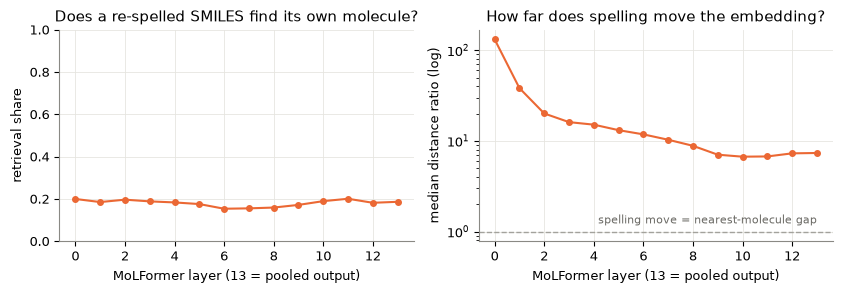

layer,hidden_0,hidden_1,hidden_2,hidden_3,hidden_4,hidden_5,hidden_6,hidden_7,hidden_8,hidden_9,hidden_10,hidden_11,hidden_12,pooler
retrieval_share,0.200,0.185,0.196,0.188,0.183,0.176,0.154,0.155,0.159,0.172,0.190,0.201,0.182,0.186
median_distance_ratio,132.133,38.273,20.110,16.134,15.128,13.156,11.824,10.316,8.842,7.055,6.707,6.747,7.299,7.366


In [5]:
inv = pd.read_csv(f"{R}/probes_invariance.csv")
inv["layer_no"] = range(len(inv))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3))
axes[0].plot(inv["layer_no"], inv["retrieval_share"], marker="o", ms=4, color=COLORS["molformer"])
axes[0].set(ylim=(0, 1), xlabel="MoLFormer layer (13 = pooled output)", ylabel="retrieval share",
            title="Does a re-spelled SMILES find its own molecule?")
axes[1].semilogy(inv["layer_no"], inv["median_distance_ratio"], marker="o", ms=4, color=COLORS["molformer"])
axes[1].axhline(1, color=GREY, ls="--", lw=1)
axes[1].text(13, 1.15, "spelling move = nearest-molecule gap", ha="right", va="bottom", color="#6b6a65", fontsize=8)
axes[1].set(xlabel="MoLFormer layer (13 = pooled output)", ylabel="median distance ratio (log)",
            title="How far does spelling move the embedding?")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_spelling_probe.png", dpi=150)
plt.show()
titled(inv[["layer", "retrieval_share", "median_distance_ratio"]].round(3).set_index("layer").T, "Spelling probe per MoLFormer layer (no labels): retrieval share and median distance ratio")

- **Re-spelling usually loses the molecule.** The retrieval share stays between 0.154 and 0.201 in every layer, so a re-spelled SMILES usually lands nearer another molecule's canonical embedding than its own.
- In layers 1–13, re-spelling moves the embedding 6.7 to 38 times further than the gap to the nearest other molecule (hidden_10: 6.707; hidden_1: 38.273). Layer 0, a context-free token average, reaches 132.
- **The frozen embeddings depend strongly on how a molecule is written.** MoLFormer was pretrained on canonical SMILES only, so this study gives it canonical SMILES throughout, a choice fixed in advance.

**Chain length.** Within the n-alkanes (C1–C44), 1-alcohols and 1-amines, do consecutive homologues stay distinguishable beyond eight carbons, where binary Morgan bits stop changing? The table shows the median distance between consecutive homologues up to and beyond C8, and the share of steps beyond C8 that leave the representation unchanged. MoLFormer is shown at layer 1, the layer the familiar-chemistry Ridge models chose (section 4), and at its pooled output.

In [6]:
chain = pd.read_csv(f"{R}/probes_chain_length.csv")
show = chain[chain["representation"].isin(["morgan_bits", "morgan_counts", "hidden_1", "pooler"])]
titled(show.set_index(["series", "representation"])[["n", "chain_lengths", "median_step_distance_upto_C8",
                                              "median_step_distance_beyond_C8",
                                              "share_steps_beyond_C8_unchanged"]].round(4), "Chain-length probe (no labels): distance between consecutive homologues, up to and beyond C8")

- **Binary Morgan bits never change beyond C8** (share unchanged 1.0 in all three series). Morgan counts and both MoLFormer layers change at every step (share 0.0).
- **MoLFormer separates long chains, but compressed.** For n-alkanes at the pooled output, the median step falls from 0.0913 up to C8 to 0.0075 beyond it; at layer 1, from 0.0071 to 0.0006.
- Morgan counts also change at every step, but by tiny cosine distances beyond C8 (≤ 0.0003 in the table): one more CH₂ barely changes a vector dominated by the CH₂ count.

## 4. Familiar chemistry

Every representation was fitted with both regressors on the same 15 folds and the same inner folds. For MoLFormer, Ridge also chose the layer in the inner cross-validation, and XGBoost reused that layer. Each point below is one fold's test MAE. The dashed grey line is the feature study's ensemble (curated descriptors plus a family input, averaging Ridge, XGBoost and a neural network) on the same folds, for reference.

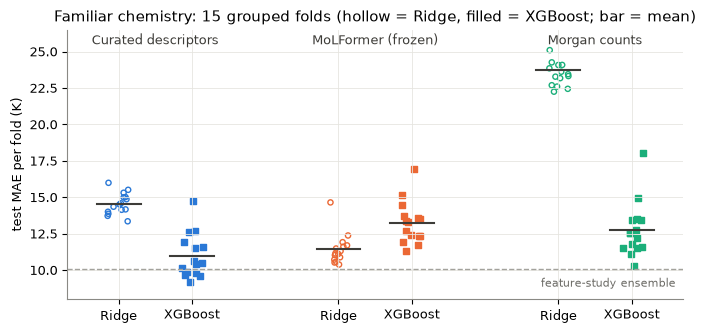

,mean,std
reference,,
"curated (log) + family ensemble (feature study, ungrouped inner CV)",10.08,1.06
molecular weight (Ridge),26.13,1.41
training mean,61.02,4.44


In [7]:
fam = preds[preds["regime"] == "familiar"]
fold_mae = fam.groupby(["representation", "regressor", "task"])["abs_err"].mean().reset_index()
ref_fold = refs[refs["regime"] == "familiar"].groupby(["reference", "task"])["abs_err"].mean()

fig, ax = plt.subplots(figsize=(7, 3.4))
rng = np.random.default_rng(0)
for i, r in enumerate(REPS):
    for j, (reg, marker) in enumerate([("ridge", "o"), ("xgboost", "s")]):
        v = fold_mae[(fold_mae["representation"] == r) & (fold_mae["regressor"] == reg)]["abs_err"]
        x = i * 3 + j
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(v)), v, s=14, marker=marker, color=COLORS[r],
                   facecolors="none" if reg == "ridge" else COLORS[r], linewidths=1)
        ax.plot([x - 0.3, x + 0.3], [v.mean()] * 2, color="#3d3c38", lw=1.5)
ensemble = ref_fold.xs("curated (log) + family ensemble (feature study, ungrouped inner CV)").mean()
ax.axhline(ensemble, color=GREY, ls="--", lw=1)
ax.text(7.6, ensemble - 0.6, "feature-study ensemble", color="#6b6a65", fontsize=8, ha="right", va="top")
ax.set_xticks([0, 1, 3, 4, 6, 7], ["Ridge", "XGBoost"] * 3)
for i, r in enumerate(REPS):
    ax.text(i * 3 + 0.5, 25.5, NAMES[r], ha="center", color="#3d3c38", fontsize=9)
ax.set(ylabel="test MAE per fold (K)", ylim=(8, 26.5), xlim=(-0.7, 7.7),
       title="Familiar chemistry: 15 grouped folds (hollow = Ridge, filled = XGBoost; bar = mean)")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_familiar_folds.png", dpi=150)
plt.show()

table = fold_mae.groupby(["representation", "regressor"])["abs_err"].agg(["mean", "std"]).round(2).unstack()
chosen_reg = pd.read_csv(f"{F}/best_selection.csv").query("regime == 'familiar'")
table["best pipeline (folds)"] = chosen_reg.groupby("representation")["regressor"].agg(lambda s: s.value_counts().to_dict())
display(titled(table.rename(index=NAMES), "Familiar chemistry: test MAE (K), mean and SD over 15 folds"))
titled(ref_fold.groupby("reference").agg(["mean", "std"]).round(2), "Familiar chemistry, reference models: test MAE (K), mean and SD over 15 folds")

- **XGBoost helps the conventional features but not the embeddings.** It beats Ridge for the curated descriptors (14.56 → 11.00 K) and Morgan counts (23.71 → 12.75 K), but not for MoLFormer (11.43 → 13.25 K). The inner cross-validation picked these same regressors in all 15 folds.
- **The best pipelines are close:** curated descriptors 11.00 ± 1.51 K, MoLFormer 11.43 ± 1.05 K, Morgan counts 12.75 ± 1.86 K. The gap between the first two (0.43 K) is well inside one fold SD.
- None beats the feature study's ensemble, at 10.08 ± 1.06 K. Molecular weight alone scores 26.13 K and the training mean 61.02 K.

**Which MoLFormer layer?** Ridge was fitted on every layer, each with its own penalty chosen in the inner cross-validation. The figure shows each layer's test MAE, averaged over the 15 folds; it is a diagnostic only, because the results above use the layer chosen in the inner cross-validation.

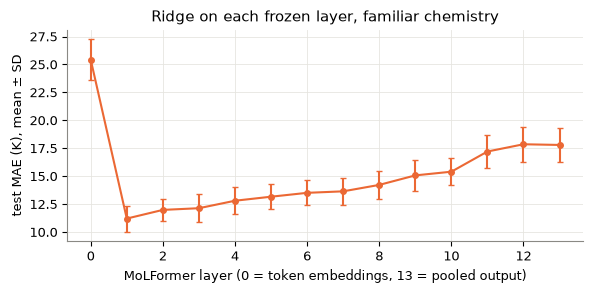

layer chosen in the inner CV, per fold: {1: 13, 2: 2}


layer,0,1,2,3,4,5,6,7,8,9,10,11,12,13
mean,25.43,11.21,11.99,12.14,12.81,13.17,13.51,13.65,14.22,15.08,15.41,17.21,17.86,17.80
std,1.82,1.17,1.01,1.26,1.19,1.13,1.12,1.21,1.28,1.36,1.19,1.45,1.56,1.54


In [8]:
probe = pd.read_csv(f"{F}/layer_probe.csv")
by_layer = probe.groupby("layer")["test_mae"].agg(["mean", "std"])
chosen = pd.read_csv(f"{F}/ridge_selection.csv").query("representation == 'molformer' and regime == 'familiar'")
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(by_layer.index, by_layer["mean"], yerr=by_layer["std"], marker="o", ms=4, capsize=2,
            color=COLORS["molformer"], lw=1.5)
ax.set(xlabel="MoLFormer layer (0 = token embeddings, 13 = pooled output)", ylabel="test MAE (K), mean ± SD",
       title="Ridge on each frozen layer, familiar chemistry")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_layer_probe.png", dpi=150)
plt.show()
print("layer chosen in the inner CV, per fold:", chosen["layer"].astype(int).value_counts().sort_index().to_dict())
titled(by_layer.round(2).T, "Frozen MoLFormer + Ridge on each layer: test MAE (K), mean and SD over 15 folds (diagnostic)")

- Test MAE is lowest at layer 1 (11.21 ± 1.17 K). It rises steadily to 17.86 ± 1.56 K at layer 12 and 17.80 ± 1.54 K for the pooled output. Layer 0, the context-free token average, is worst at 25.43 ± 1.82 K.
- **The inner cross-validation agreed:** each fold's inner cross-validation, using only its training data, chose layer 1 in 13 of the 15 folds and layer 2 in the other 2.
- One pass of context removes most of the error (25.43 → 11.21 K). Deeper layers, trained to predict masked tokens, are progressively less useful for boiling point.

## 5. Unseen functional groups

Each family is predicted by models trained on the other three, with hyperparameters chosen by leave-one-family-out inside the training families, so tuning rewards extrapolation. The bars show each representation's best pipeline; the grey tick is a Ridge model on molecular weight alone.

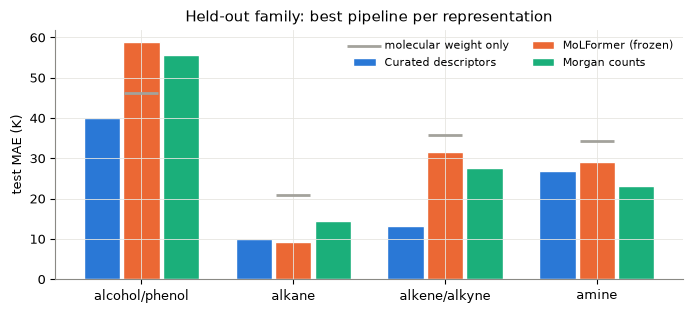

representation,Curated descriptors,MoLFormer (frozen),Morgan counts
task,,,
alcohol/phenol,40.0,59.0,55.8
alkane,10.0,9.2,14.4
alkene/alkyne,13.3,31.5,27.7
amine,26.8,29.0,23.2
mean over families,22.5,32.2,30.3


best-pipeline regressor: {'curated': 'xgboost', 'molformer': 'ridge', 'morgan': 'xgboost'}


In [9]:
hold = best[best["regime"] == "holdout"].groupby(["task", "representation"])["abs_err"].mean().unstack()[REPS]
mw = refs[(refs["regime"] == "holdout") & (refs["reference"] == "molecular weight (Ridge)")].groupby("task")["abs_err"].mean()
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(hold))
for k, r in enumerate(REPS):
    ax.bar(x + (k - 1) * 0.26, hold[r], width=0.24, color=COLORS[r], label=NAMES[r], edgecolor="white", linewidth=1)
ax.scatter(x, mw.loc[hold.index], marker="_", s=600, color=GREY, linewidths=2, label="molecular weight only", zorder=3)
ax.set_xticks(x, hold.index)
ax.set(ylabel="test MAE (K)", title="Held-out family: best pipeline per representation")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_family_holdout.png", dpi=150)
plt.show()
regressors = best[best["regime"] == "holdout"].groupby("representation")["regressor"].first()
out = hold.round(1).rename(columns=NAMES)
out.loc["mean over families"] = hold.mean().round(1).rename(NAMES)
display(titled(out, "Held-out families: test MAE (K) of each representation's best pipeline"))
print("best-pipeline regressor:", regressors.to_dict())

- **Averaged over the four families, the curated descriptors lead:** 22.5 K, against 30.3 K for Morgan counts and 32.2 K for MoLFormer.
- MoLFormer matches the descriptors on alkanes (9.2 vs 10.0 K) but is far worse on alcohols/phenols (59.0 vs 40.0 K) and alkenes/alkynes (31.5 vs 13.3 K). On alcohols/phenols it's even worse than molecular weight alone (grey tick).
- Morgan counts do best on amines (23.2 K, vs 26.8 K for the descriptors and 29.0 K for MoLFormer).
- **The expectation that Morgan counts would fail worst on unseen families isn't borne out.** With XGBoost as its best pipeline, Morgan isn't the worst on average; MoLFormer is.

## 6. Unseen elements and rings

The NIST compounds lie far from the training data: none of the 1,250 training molecules has a ring or a halogen. Each panel plots a representation's best-pipeline predictions against the NIST label, with the grey line marking a perfect prediction.

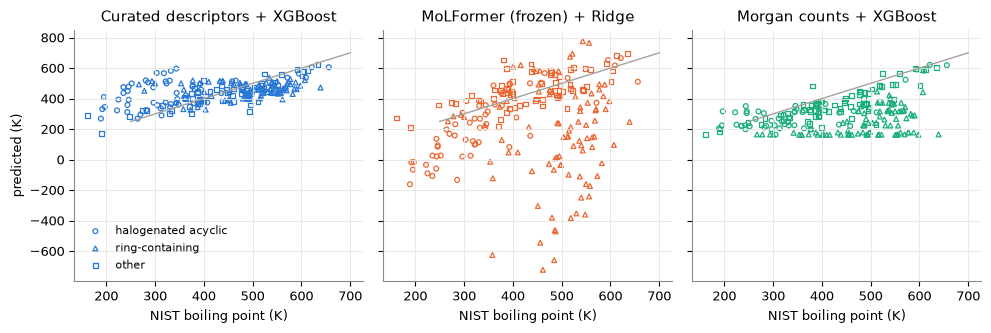

representation,Curated descriptors,MoLFormer (frozen),Morgan counts
subgroup,,,
halogenated acyclic,105.5,146.2,72.3
other,43.9,78.3,72.3
ring-containing,78.3,389.1,254.4
all 211,74.7,224.8,147.4
min prediction (K),171.7,-722.4,161.9


training-mean reference MAE: 94.0 K


,name,subgroup,y_true,y_pred
5183,Iodobenzene,ring-containing,461.6,-722.4
5205,2-Iodotoluene,ring-containing,484.7,-658.6
5181,4-Fluoroiodobenzene,ring-containing,456.2,-544.7
5206,Fluorobenzene,ring-containing,358.0,-625.1
5194,4-Iodotoluene,ring-containing,487.6,-470.1


In [10]:
nb = best[best["regime"] == "nist"].assign(subgroup=lambda d: d["key"].map(subgroup))
markers = {"halogenated acyclic": "o", "ring-containing": "^", "other": "s"}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, r in zip(axes, REPS):
    d = nb[nb["representation"] == r]
    for g, m in markers.items():
        s = d[d["subgroup"] == g]
        ax.scatter(s["y_true"], s["y_pred"], s=12, marker=m, facecolors="none", edgecolors=COLORS[r], linewidths=0.9,
                   label=g)
    ax.plot([250, 700], [250, 700], color=GREY, lw=1)
    ax.set(title=f"{NAMES[r]} + {REG[d['regressor'].iloc[0]]}", xlabel="NIST boiling point (K)")
axes[0].set_ylabel("predicted (K)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_nist.png", dpi=150)
plt.show()

table = nb.groupby(["subgroup", "representation"])["abs_err"].mean().unstack()[REPS]
table.loc["all 211"] = nb.groupby("representation")["abs_err"].mean()[REPS]
table.loc["min prediction (K)"] = nb.groupby("representation")["y_pred"].min()[REPS]
mean_ref = refs[(refs["regime"] == "nist") & (refs["reference"] == "training mean")]["abs_err"].mean()
display(titled(table.round(1).rename(columns=NAMES), "NIST: test MAE (K) of each best pipeline, by subgroup (last row: lowest prediction, K)"))
print(f"training-mean reference MAE: {mean_ref:.1f} K")
titled(nb[nb["representation"] == "molformer"].nlargest(5, "abs_err").assign(
    name=lambda d: d["key"].map(dict(zip("nist:" + nist.index.astype(str), nist["cmpdname"]))))[
    ["name", "subgroup", "y_true", "y_pred"]].round(1), "NIST: frozen MoLFormer's 5 largest errors (y_true = measured, y_pred = predicted, K)")

- **Only the descriptors beat simply predicting the training mean** (74.7 vs 94.0 K). MoLFormer reaches 224.8 K and Morgan counts 147.4 K.
- MoLFormer's failure is concentrated on ring compounds (389.1 K MAE). It predicts physically impossible negative temperatures, down to −722.4 K for iodobenzene: a linear model extrapolating far outside training data that has no rings or iodine.
- Morgan counts with XGBoost can't extrapolate either: their predictions never go below 161.9 K, and ring compounds pile up near that floor (254.4 K MAE). On halogenated acyclic compounds, though, Morgan counts are best (72.3 K, vs 105.5 K for the descriptors and 146.2 K for MoLFormer).

**Is it the regressor?** The inner cross-validation chose Ridge for MoLFormer everywhere, because it beat XGBoost on familiar chemistry. Trees can't predict outside the range of the training labels, so the controlled XGBoost results (not the best pipeline, shown for comparison) separate the representation from the linear extrapolation:

In [11]:
pn = preds[preds["regime"] == "nist"].assign(subgroup=lambda d: d["key"].map(subgroup))
titled(pn.groupby(["subgroup", "representation", "regressor"])["abs_err"].mean().unstack(["representation", "regressor"])[REPS].round(1), "NIST: test MAE (K) by subgroup, every representation and regressor")

- **Most of MoLFormer's failure is the linear extrapolation.** With XGBoost, its ring-compound error falls from 389.1 to 109.7 K. It still trails the descriptors' best on rings (78.3 K, XGBoost), and on halogenated acyclic compounds (115.3 vs 69.3 K, descriptors with Ridge).
- The descriptors do better with Ridge than XGBoost on halogenated acyclic compounds (69.3 vs 105.5 K). **A pipeline chosen on familiar data isn't necessarily the best one out of distribution,** a limitation of selecting it by inner cross-validation.
- No combination predicts the NIST compounds well. The best subgroup errors are 43.9–78.3 K, against label noise of about half a kelvin (section 1).

## 7. Fine-tuning MoLFormer: does training the whole encoder help?

A frozen encoder can only offer what pretraining put into its vectors. **Fine-tuning** trains all 44.4 million MoLFormer weights on the boiling points, with a small two-layer network on its pooled output. The design was fixed before any run:
- **Validation:** 15% of each training fold is held out, as whole structure groups and in proportion to the families, and split in half. One half decides when to stop training and which of three learning rates (1e-5, 3e-5, 1e-4) to keep; the other half is untouched until the intervals of section 10.
- **Spelling augmentation:** one molecule can be written as many valid SMILES strings, and section 3 showed the frozen vectors change with the spelling. During training, each molecule gets a new random spelling every epoch.
- **Training:** at most 30 epochs, stopping after 5 epochs without improvement on the stopping half; 3 random seeds per fold at the chosen learning rate. All runs were on a CPU and are exactly reproducible.
- **Inference:** predictions from the canonical SMILES, as for the frozen model. A **spelling-averaged** prediction, the mean over 10 random spellings, is reported alongside.

The fine-tuned MAE is a single run's MAE, averaged over the 3 seeds. The figure pairs each familiar fold's fine-tuned MAE with the frozen best pipeline's (MoLFormer + Ridge) on the same test molecules.

C5 compares two complete pipelines, each in its usual form, and they differ in more than the training of the encoder: the fine-tuned model also has a neural-network head instead of Ridge, and reads the pooled output instead of layer 1. The end of this section separates the three.

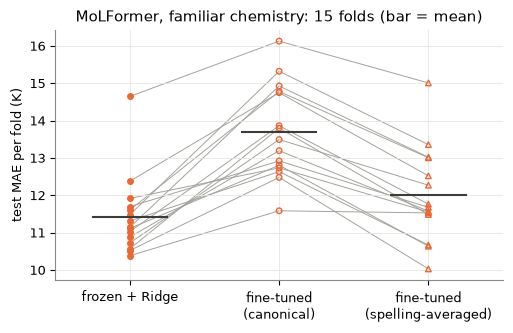

,mean,SD over folds
"frozen MoLFormer + Ridge, full training fold",11.43,1.05
"frozen MoLFormer + Ridge, same 85% as fine-tuning",11.64,1.40
"fine-tuned, canonical",13.70,1.26
"fine-tuned, spelling-averaged",12.01,1.25


In [12]:
ftp = pd.read_csv(f"{FT}/predictions.csv")
ftp["abs_err"] = (ftp["y_pred"] - ftp["y_true"]).abs()
ft_run = ftp.groupby(["regime", "task", "inference", "seed"])["abs_err"].mean()
ft_task = ft_run.groupby(["regime", "task", "inference"]).mean().unstack("inference")   # single-seed MAE, mean over seeds
c5 = pd.read_csv(f"{FT}/c5_folds.csv").set_index("task")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
fam_ft = ft_task.loc["familiar"]
for task in c5.index:
    ys = [c5.loc[task, "frozen_mae"], fam_ft.loc[task, "canonical"], fam_ft.loc[task, "tta"]]
    ax.plot([0, 1, 2], ys, color=GREY, lw=0.7, zorder=1)
ax.scatter(np.zeros(len(c5)), c5["frozen_mae"], s=16, color=COLORS["molformer"], zorder=2)
ax.scatter(np.ones(len(c5)), fam_ft.loc[c5.index, "canonical"], s=16, facecolors="none",
           edgecolors=COLORS["molformer"], linewidths=1, zorder=2)
ax.scatter(np.full(len(c5), 2), fam_ft.loc[c5.index, "tta"], s=16, marker="^", facecolors="none",
           edgecolors=COLORS["molformer"], linewidths=1, zorder=2)
for x, v in enumerate([c5["frozen_mae"], fam_ft["canonical"], fam_ft["tta"]]):
    ax.plot([x - 0.25, x + 0.25], [v.mean()] * 2, color="#3d3c38", lw=1.5)
ax.set_xticks([0, 1, 2], ["frozen + Ridge", "fine-tuned\n(canonical)", "fine-tuned\n(spelling-averaged)"])
ax.set(ylabel="test MAE per fold (K)", xlim=(-0.5, 2.5), title="MoLFormer, familiar chemistry: 15 folds (bar = mean)")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_finetune_folds.png", dpi=150)
plt.show()

matched = pd.read_csv(f"{FT}/frozen_matched_predictions.csv")
matched_fold = (matched["y_pred"] - matched["y_true"]).abs().groupby(matched["task"]).mean()
titled(pd.DataFrame({"mean": [c5["frozen_mae"].mean(), matched_fold.mean(), fam_ft["canonical"].mean(), fam_ft["tta"].mean()],
              "SD over folds": [c5["frozen_mae"].std(), matched_fold.std(), fam_ft["canonical"].std(), fam_ft["tta"].std()]},
             index=["frozen MoLFormer + Ridge, full training fold", "frozen MoLFormer + Ridge, same 85% as fine-tuning",
                    "fine-tuned, canonical", "fine-tuned, spelling-averaged"]).round(2), "Familiar chemistry: test MAE (K) of fine-tuned and frozen MoLFormer, mean and SD over 15 folds")

- **Fine-tuning makes MoLFormer worse on familiar chemistry:** 13.70 ± 1.26 K against 11.43 ± 1.05 K frozen (+2.27 K). Every one of the 15 lines in the figure rises from frozen to fine-tuned.
- **Holding out 15% for validation is not the cause:** frozen MoLFormer refitted on the same 85% scores 11.64 ± 1.40 K, only 0.21 K above the full training fold (11.43 → 11.64 K).
- **The fine-tuned model still depends on spelling:** averaging over 10 random spellings brings it from 13.70 to 12.01 K, still above the frozen 11.43 K.

**Beyond familiar chemistry.** The same recipe was run on each held-out family, on the NIST set (trained on all 1,250) and on the 250-molecule training subsets of section 8 (one per fold). These runs are descriptive. The frozen columns are each representation's best pipeline in the same setting.

In [13]:
lc_best = pd.read_csv(f"{LC}/best_predictions.csv")
lc_best["abs_err"] = (lc_best["y_pred"] - lc_best["y_true"]).abs()
frozen_task = best.groupby(["regime", "task", "representation"])["abs_err"].mean().unstack()
n250 = lc_best[lc_best["draw"] == 0].query("size == 250").groupby(["fold", "representation"])["abs_err"].mean().unstack()
rows = {}
for label, regime in [("familiar (15 folds)", "familiar"), ("held-out families (mean of 4)", "holdout"), ("NIST (211)", "nist")]:
    rows[label] = {"fine-tuned, canonical": ft_task.loc[regime, "canonical"].mean(),
                   "fine-tuned, spelling-averaged": ft_task.loc[regime, "tta"].mean(),
                   **{f"frozen {NAMES[r].split(' (')[0]}": frozen_task.loc[regime, r].mean() for r in REPS}}
rows["n = 250 (5 folds, draw 0)"] = {"fine-tuned, canonical": ft_task.loc["learning_curve", "canonical"].mean(),
                                     "fine-tuned, spelling-averaged": ft_task.loc["learning_curve", "tta"].mean(),
                                     **{f"frozen {NAMES[r].split(' (')[0]}": n250[r].mean() for r in REPS}}
display(titled(pd.DataFrame(rows).T.round(2), "Test MAE (K) per setting: fine-tuned (one run, mean over 3 seeds) and frozen best pipelines"))
hold_ft = ft_task.loc["holdout"].join(frozen_task.loc["holdout"])
titled(hold_ft[["canonical", "tta"] + REPS].rename(columns={"canonical": "fine-tuned, canonical", "tta": "fine-tuned, spelling-averaged",
                                                    **NAMES}).round(2), "Held-out families: test MAE (K) per family, fine-tuned and frozen")

,"fine-tuned, canonical","fine-tuned, spelling-averaged",frozen Curated descriptors,frozen MoLFormer,frozen Morgan counts
familiar (15 folds),13.70,12.01,11.00,11.43,12.75
held-out families (mean of 4),29.46,27.29,22.51,32.18,30.26
NIST (211),79.05,78.30,74.68,224.81,147.41
"n = 250 (5 folds, draw 0)",22.79,18.94,14.30,13.84,20.61


,"fine-tuned, canonical","fine-tuned, spelling-averaged",Curated descriptors,MoLFormer (frozen),Morgan counts
task,,,,,
alcohol/phenol,60.53,58.20,40.01,58.98,55.77
alkane,11.49,10.62,9.97,9.23,14.35
alkene/alkyne,19.44,15.35,13.31,31.48,27.69
amine,26.39,24.99,26.76,29.03,23.21


- **Held-out families:** fine-tuning beats frozen MoLFormer on average (29.46 vs 32.18 K) but not the curated descriptors (22.51 K). Its gain is concentrated in alkenes/alkynes (31.48 → 19.44 K); alcohols/phenols stay the hardest family (60.53 K fine-tuned, 58.98 frozen, 40.01 curated).
- **NIST:** fine-tuning removes the frozen Ridge readout's runaway extrapolation (224.81 → 79.05 K), coming close to the curated descriptors (74.68 K) without beating them.
- **With 250 training molecules,** fine-tuning is far behind: 22.79 K against 13.84 K for frozen MoLFormer and 14.30 K for curated descriptors on the same subsets.

**Exploratory: why do fine-tuned runs lose?** This was examined after seeing the results, so it is not part of any test. The table lists the familiar folds whose 3 seeds disagree most, and the effect of averaging the 3 seeds' predictions (an ensemble that costs three times the training).

In [14]:
sel = pd.read_csv(f"{FT}/selection.csv")
runs = ft_run.loc["familiar"].xs("canonical", level="inference").rename("test MAE").reset_index()
runs = runs.merge(sel[sel["chosen_lr"]][["task", "seed", "lr", "best_epoch", "epochs_run", "best_stop_mae"]], on=["task", "seed"])
runs["lr"] = runs["lr"].map("{:g}".format)
spread = runs.groupby("task")["test MAE"].agg(["mean", "std", "min", "max"]).sort_values("std", ascending=False)
display(titled(spread.head(4).round(2), "Fine-tuning: familiar folds with the largest spread over 3 seeds (test MAE, K)"))
display(titled(runs.nlargest(3, "test MAE").round(2), "Fine-tuning: the 3 worst single runs (test MAE and stopping-half MAE, K)"))
fam = ftp[(ftp["regime"] == "familiar")]
ens = fam.groupby(["inference", "task", "key"]).agg(y_true=("y_true", "first"), y_pred=("y_pred", "mean")).reset_index()
ens_fold = (ens["y_pred"] - ens["y_true"]).abs().groupby([ens["inference"], ens["task"]]).mean()
print("3-seed ensemble, fold MAE mean ± SD:",
      {m: f"{ens_fold[m].mean():.2f} ± {ens_fold[m].std():.2f}" for m in ("canonical", "tta")})
print("Spearman, stopping-half MAE vs test MAE over the 45 runs:", round(runs[["best_stop_mae", "test MAE"]].corr("spearman").iloc[0, 1], 2))

,mean,std,min,max
task,,,,
r1f0,13.49,4.45,9.18,18.06
r2f4,15.32,3.99,12.35,19.86
r0f3,14.78,3.83,11.31,18.89
r2f3,13.86,1.64,12.49,15.67


,task,seed,test MAE,lr,best_epoch,epochs_run,best_stop_mae
44,r2f4,2,19.86,1e-05,5,11,17.47
11,r0f3,2,18.89,0.0001,2,8,23.86
17,r1f0,2,18.06,0.0001,1,7,21.42


3-seed ensemble, fold MAE mean ± SD: {'canonical': '11.49 ± 1.25', 'tta': '10.45 ± 1.30'}
Spearman, stopping-half MAE vs test MAE over the 45 runs: 0.42


- **Seeds disagree:** on fold r1f0 the three runs score 9.18 to 18.06 K (SD 4.45). The three worst runs all stopped early, with their best epoch at 1, 2 or 5 and a stopping-half MAE of 17.47 to 23.86 K.
- **The stopping half is a noisy guide:** its MAE ranks the 45 runs' test MAE only moderately (Spearman 0.42).
- **Averaging the 3 seeds' predictions** gives 11.49 ± 1.25 K (canonical) and 10.45 ± 1.30 K (spelling-averaged), level with or below the frozen 11.43 K. This was found after the results and costs three times the training, so it is a lead for further work, not a tested result.

**Exploratory: is it the encoder, the head or the layer?** Fine-tuning changes three things at once: it trains the encoder's weights, it replaces Ridge with a small neural-network head (a multilayer perceptron, MLP), and it reads the pooled output instead of layer 1. (Training size, 85% against 100% of the fold, is covered by the matched check above.) To separate them, the fine-tuning head was trained on the **frozen** embeddings, on each fold's same fit and stopping rows, at layer 1 and at the pooled output, with two recipes:
- **R1, the fine-tuning recipe:** learning rates 1e-5, 3e-5 and 1e-4, at most 30 epochs, patience 5. Only the training of the encoder differs from fine-tuning.
- **R2, room to converge:** learning rates 1e-4 to 3e-3, at most 300 epochs, patience 20. A fresh head on fixed features needs more steps than one on a moving encoder, so this is the fair test of MLP against Ridge.

As in fine-tuning, seed 0 is run at each learning rate, the best rate on the stopping half is kept, and seeds 1 and 2 follow; the MAE is a single run's, averaged over the 3 seeds. Ridge was refitted with each fold's layer-probe penalty on the same fit rows. One difference remains: the frozen heads train on canonical embeddings, while fine-tuning saw a new random spelling every epoch. This was chosen after seeing C5, so it is exploratory: raw p-values, and C5 is unchanged (`scripts/run_head_control.py`).

In [15]:
HC = f"{FT}/head_control"
hc_fold = pd.read_csv(f"{HC}/folds.csv").set_index("task")
hc_runs = pd.read_csv(f"{HC}/runs.csv")
HC_ROWS = [("frozen_best", "frozen", "Ridge", "chosen in inner CV", "100%"),
           ("ridge_hidden_1_full", "frozen", "Ridge", "layer 1", "100%"),
           ("ridge_hidden_1_matched", "frozen", "Ridge", "layer 1", "85%"),
           ("mlp_hidden_1_R1", "frozen", "MLP, R1", "layer 1", "85%"),
           ("mlp_hidden_1_R2", "frozen", "MLP, R2", "layer 1", "85%"),
           ("ridge_pooler_full", "frozen", "Ridge", "pooled output", "100%"),
           ("ridge_pooler_matched", "frozen", "Ridge", "pooled output", "85%"),
           ("mlp_pooler_R1", "frozen", "MLP, R1", "pooled output", "85%"),
           ("mlp_pooler_R2", "frozen", "MLP, R2", "pooled output", "85%"),
           ("finetuned", "trained", "MLP (fine-tuning)", "pooled output", "85%")]
hc_tab = pd.DataFrame([{"encoder": e, "head": h, "layer read": l, "training rows": n,
                        "mean": hc_fold[m].mean(), "SD over folds": hc_fold[m].std()} for m, e, h, l, n in HC_ROWS]).round(2)
display(titled(hc_tab, "Familiar chemistry: test MAE (K) by encoder, head and layer, mean and SD over 15 folds"))

ch = hc_runs[hc_runs["chosen_lr"]]
conv = ch.groupby(["layer", "recipe"]).agg(
    chosen_rate=("lr", lambda s: ", ".join(f"{k:g} ({v // 3})" for k, v in s.value_counts().sort_index().items())),
    median_best_epoch=("best_epoch", "median"), median_epochs_run=("epochs_run", "median"),
    runs_at_epoch_limit=("epochs_run", lambda s: int((s == {"R1": 30, "R2": 300}[ch.loc[s.index, "recipe"].iloc[0]]).sum())))
display(titled(conv, "Frozen MLP heads: chosen learning rate (folds), and training length of the 45 kept runs per row"))

hcc = pd.read_csv(f"{HC}/contrasts.csv")
hcc["estimate [95% interval] (K)"] = hcc.apply(lambda r: f"{r['estimate']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]", axis=1)
hcc["p (raw)"] = hcc["p_raw"].map(lambda p: f"{p:.4f}" if p < 0.001 else f"{p:.3f}")
hcc["folds where first is better"] = hcc["folds_first_better"].astype(str) + " / " + hcc["n_folds"].astype(str)
titled(hcc.set_index("contrast")[["first", "second", "estimate [95% interval] (K)", "p (raw)", "folds where first is better"]],
       "Paired difference in test MAE (K), first − second over 15 folds (negative = first better), corrected resampled t-test")

,encoder,head,layer read,training rows,mean,SD over folds
0,frozen,Ridge,chosen in inner CV,100%,11.43,1.05
1,frozen,Ridge,layer 1,100%,11.21,1.17
2,frozen,Ridge,layer 1,85%,11.50,1.28
3,frozen,"MLP, R1",layer 1,85%,13.89,1.57
4,frozen,"MLP, R2",layer 1,85%,12.62,1.36
5,frozen,Ridge,pooled output,100%,17.80,1.54
6,frozen,Ridge,pooled output,85%,18.33,1.65
7,frozen,"MLP, R1",pooled output,85%,17.08,1.97
8,frozen,"MLP, R2",pooled output,85%,15.01,1.49
9,trained,MLP (fine-tuning),pooled output,85%,13.70,1.26


,first,second,estimate [95% interval] (K),p (raw),folds where first is better
contrast,,,,,
head at the pooled output (R1),mlp_pooler_R1,ridge_pooler_matched,"-1.25 [-2.52, +0.01]",0.052,14 / 15
head at the pooled output (R2),mlp_pooler_R2,ridge_pooler_matched,"-3.32 [-4.84, -1.80]",0.0003,15 / 15
encoder training (R1),finetuned,mlp_pooler_R1,"-3.38 [-5.50, -1.26]",0.004,15 / 15
encoder training (R2),finetuned,mlp_pooler_R2,"-1.31 [-2.99, +0.36]",0.115,13 / 15
head at layer 1 (R1),mlp_hidden_1_R1,ridge_hidden_1_matched,"+2.39 [+0.72, +4.07]",0.008,0 / 15
head at layer 1 (R2),mlp_hidden_1_R2,ridge_hidden_1_matched,"+1.13 [-0.02, +2.28]",0.054,1 / 15
layer with an MLP head (R1),mlp_hidden_1_R1,mlp_pooler_R1,"-3.19 [-4.92, -1.46]",0.001,15 / 15
layer with an MLP head (R2),mlp_hidden_1_R2,mlp_pooler_R2,"-2.39 [-3.96, -0.82]",0.006,15 / 15


- **The read-out layer, not the training of the encoder, drives most of the C5 gap.** With the same frozen embeddings and the same MLP head (recipe R2), layer 1 beats the pooled output by 2.39 K [−3.96, −0.82] (12.62 against 15.01 K), in all 15 folds.
- **Training the encoder helps, but less than the layer costs.** Fine-tuned 13.70 K against 15.01 K for a frozen pooled output with the same head (R2): −1.31 K [−2.99, +0.36], better in 13 of 15 folds. Under the fine-tuning recipe R1 the gain looks larger (−3.38 K), but R1 under-trains a head on fixed features: 23 of 45 pooled-output runs and 18 of 45 layer-1 runs stopped at the 30-epoch limit, against none under R2.
- **The head matters, in opposite directions.** On the pooled output the MLP beats Ridge (15.01 against 18.33 K, −3.32 K, all 15 folds); on layer 1 Ridge stays ahead (11.50 against 12.62 K, +1.13 K [−0.02, +2.28], Ridge better in 14 of 15 folds).
- **Step by step on the same 85% of each fold:** frozen layer 1 + Ridge 11.50 K → MLP head 12.62 K (+1.13) → pooled output 15.01 K (+2.39) → encoder trained 13.70 K (−1.31). Fine-tuning with the usual head on the pooled output gives up the early-layer advantage the frozen probe found, and training the encoder wins back only part of it. A fine-tuned head reading an early layer, or mixing layers, is the untested next variant.

## 8. Learning curves: 100 to ~1,000 training molecules

A pretrained representation might matter most when labels are scarce. Each repeat-0 fold was trained on nested, family-stratified subsets of 100, 250 and 500 molecules, three random draws each, always tested on the full fold. Every choice (regressor, penalty, MoLFormer layer) was made inside the subset. The full-size point is section 4's repeat-0 result (5 folds, one draw), and fine-tuned MoLFormer appears at n = 250 and full size.

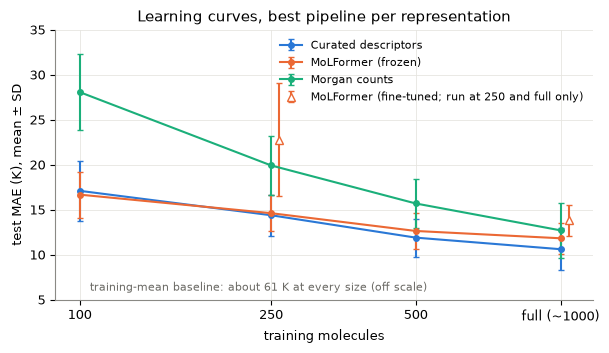

,Curated descriptors,MoLFormer (frozen),Morgan counts,training mean,runs
size,,,,,
100,17.10,16.68,28.07,61.47,15
250,14.39,14.62,19.92,61.06,15
500,11.90,12.64,15.69,60.97,15
full,10.61,11.83,12.71,60.98,5


In [16]:
curves = pd.read_csv(f"{LC}/curves.csv")
curves["size"] = curves["size"].astype(str)
full_n = splits.groupby("fold_r0").size().rsub(len(splits)).mean()                 # ~1,000 training molecules
xpos = {"100": 100, "250": 250, "500": 500, "full": full_n}
bestc = curves[curves["regressor"] == "best"]
stats_ = bestc.groupby(["representation", "size"])["mae"].agg(mean="mean", std="std", runs="count").reset_index()
h5 = pd.read_csv(f"{LC}/h5_finetuned_vs_frozen.csv")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
for r in REPS:
    d = stats_[stats_["representation"] == r].set_index("size").loc[list(xpos)]
    x = [xpos[s] for s in d.index]
    ax.errorbar(x, d["mean"], yerr=d["std"], color=COLORS[r], marker="o", ms=4, capsize=2, lw=1.5, label=NAMES[r])
ft_pts = h5.groupby("size")["finetuned"].agg(["mean", "std"]).loc[["250", "full"]]
ax.errorbar([xpos[s] * 1.04 for s in ft_pts.index], ft_pts["mean"], yerr=ft_pts["std"], color=COLORS["molformer"],
            marker="^", mfc="white", ms=6, capsize=2, ls="none", label="MoLFormer (fine-tuned; run at 250 and full only)")
ref = curves[curves["representation"] == "training mean"].groupby("size")["mae"].mean()
ax.text(105, 6, f"training-mean baseline: about {ref.mean():.0f} K at every size (off scale)", fontsize=8, color="#6b6a65")
ax.set_xscale("log")
ax.set_xticks(list(xpos.values()), ["100", "250", "500", f"full (~{full_n:.0f})"])
ax.minorticks_off()
ax.set(xlabel="training molecules", ylabel="test MAE (K), mean ± SD", ylim=(5, 35),
       title="Learning curves, best pipeline per representation")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_learning_curves.png", dpi=150)
plt.show()

table = stats_.pivot(index="size", columns="representation", values="mean")[REPS].loc[list(xpos)].round(2)
table.columns = [NAMES[c] for c in table.columns]
table["training mean"] = ref.loc[list(xpos)].round(2)
table["runs"] = stats_[stats_["representation"] == "curated"].set_index("size").loc[list(xpos), "runs"].values
display(titled(table, "Learning curves: test MAE (K) of each best pipeline, mean over runs"))
diffs = pd.read_csv(f"{LC}/differences.csv")
diffs["size"] = diffs["size"].astype(str)
display(titled(diffs.groupby("size")[["molformer_minus_curated", "morgan_minus_curated"]].agg(["mean", "std"]).loc[list(xpos)].round(2), "Learning curves: paired MAE difference to curated (K), mean and SD over runs (positive = worse than curated)"))
chosen = pd.read_csv(f"{LC}/best_selection.csv")
chosen["size"] = chosen["task"].str.extract(r"n(\d+)_")[0]
titled(chosen.groupby(["size", "representation"])["regressor"].value_counts().unstack().fillna(0).astype(int), "Learning curves: regressor chosen in the inner cross-validation (number of runs)")

- **Curated descriptors and frozen MoLFormer track each other at every size:** 17.10 vs 16.68 K at n = 100, 10.61 vs 11.83 K at full size. MoLFormer − curated moves from −0.42 ± 2.87 K (n = 100) through +0.23 ± 1.03 and +0.74 ± 0.95 to +1.21 ± 0.88 K (full): if anything, the pretrained representation's relative standing falls as data grows.
- **Morgan counts need the most data:** 28.07 K at n = 100, falling to 12.71 K at full size; their gap to the curated descriptors shrinks from 10.97 to 2.09 K.
- **Regressor choice shifts with size for the descriptors only:** curated descriptors take Ridge at n = 100 (15/15) and XGBoost at n = 500 (15/15); MoLFormer takes Ridge at every size (15/15); Morgan counts take XGBoost in 44 of 45 runs.
- Every curve sits far below the training-mean baseline (60.97–61.47 K).

**Fine-tuning at n = 250.** The fine-tuned model trains on about 212 of the 250 molecules (the rest validate), so it is compared both with the frozen best pipeline on all 250 and with frozen MoLFormer + Ridge refitted on the same ~212 ("matched"). Positive means fine-tuning is worse.

In [17]:
titled(h5.groupby("size")[["finetuned", "frozen_best", "frozen_matched", "minus_best", "minus_matched"]].agg(["mean", "std"]).round(2), "Fine-tuned vs frozen at n = 250 and full size: test MAE (K) and differences, mean and SD over folds")

- **With 250 molecules, fine-tuning trails frozen MoLFormer by 8.95 ± 4.35 K** (22.79 vs 13.84 K), and by 7.97 ± 4.26 K against frozen MoLFormer on the same ~212 molecules (14.82 K).
- At full size on the same repeat-0 folds the gaps are +1.98 ± 1.14 and +2.64 ± 1.35 K. **The gap widens with less data, instead of narrowing as H5 expected.**

## 9. Confirmatory comparisons C1–C5, and descriptive Morgan contrasts

These are the five tests fixed before any result. C1–C4 are MAE(frozen MoLFormer) − MAE(curated descriptors), C5 is MAE(fine-tuned) − MAE(frozen MoLFormer); positive means the first is worse.
- **C1, C4, C5** use the corrected resampled t-test of Nadeau & Bengio (2003, *Machine Learning* 52). Repeated cross-validation runs share training data, so it widens the plain t-test's variance by (1/J + n_test/n_train) over J runs. For C4 (n_train ≈ 100, n_test ≈ 250) that factor is large, so C4 can only detect large differences; the **minimum detectable difference** is the standard error (SE) × the two-sided 5% t critical value.
- **C2 and C3** average the per-family or per-subgroup differences with equal weight; their 95% confidence intervals (CI) come from 10,000 bootstrap resamples of molecules within each family or subgroup. None of the resamples crossed zero, so p < 2/10,000; Holm's correction uses that bound.
- **Holm's correction** (Holm, 1979, *Scandinavian Journal of Statistics* 6) is applied across all five at α = 0.05. A **finding** needs a Holm-adjusted p < 0.05 *and* a difference of at least 1.0 K.

In [18]:
conf = pd.read_csv(f"{R}/confirmatory.csv")
c4 = pd.read_csv(f"{LC}/c4_provisional.csv")
boot = conf["test"] == "bootstrap"
conf["p (raw)"] = [("< 0.0002" if b and p == 0 else f"{p:.3f}") for p, b in zip(conf["p_raw"], boot)]
conf["p (Holm)"] = [(f"≤ {p:.3f}" if b else f"{p:.3f}") for p, b in zip(conf["p_holm"], boot)]
conf["min. detectable (K)"] = conf["comparison"].map({"C4": round(float(c4["min_detectable"].iloc[0]), 2)})
show = conf.set_index("comparison")[["hypothesis", "contrast", "estimate", "se", "ci_low", "ci_high", "p (raw)", "p (Holm)",
                                     "min. detectable (K)", "finding"]]
titled(show.round(2), "Confirmatory tests C1–C5: difference in MAE (K), positive = first model worse")

,hypothesis,contrast,estimate,se,ci_low,ci_high,p (raw),p (Holm),min. detectable (K),finding
comparison,,,,,,,,,,
C1,H1,"frozen MoLFormer - curated (log), familiar, 15 folds",0.43,0.63,,,0.506,1.000,,False
C2,H2,"frozen MoLFormer - curated (log), held-out families, macro-average of 4",9.67,,8.40,10.95,< 0.0002,≤ 0.001,,True
C3,H3,"frozen MoLFormer - curated (log), NIST external, macro-average of 3 subgroups",128.69,,105.96,152.70,< 0.0002,≤ 0.001,,True
C4,H4,"frozen MoLFormer - curated (log), familiar, n = 100, 5 folds x 3 draws",-0.42,4.59,,,0.928,1.000,9.85,False
C5,H5,"fine-tuned - frozen MoLFormer, familiar, 15 folds",2.27,0.55,,,0.001,0.003,,True


- **Three findings, all against the language model:** frozen MoLFormer is worse than the curated descriptors on unseen families (C2, +9.67 K, 95% CI 8.40 to 10.95) and on the NIST set (C3, +128.69 K, 95% CI 105.96 to 152.70), and fine-tuning is worse than freezing (C5, +2.27 K, SE 0.55, Holm p = 0.003).
- **No difference was detected on familiar chemistry** (C1, +0.43 K, Holm p = 1.000), nor with 100 training molecules (C4, −0.42 K, Holm p = 1.000). C4 could only have detected a difference of 9.85 K or more, so it means "not detectable", not "no difference".
- **By hypothesis:** H1 (curated ≥ CLM on familiar chemistry) holds only as a tie; H2 and H3 resolve against the CLM; H4 (a CLM advantage at n = 100) finds no support at this power; H5 (fine-tuning beats frozen) is contradicted.

**Descriptive: where Morgan counts sit.** The three representations run from expert-designed to learned. The curated descriptors are global physical properties a chemist chose for boiling (size, polarity, hydrogen bonding). Morgan counts are a fixed rule with no chemistry knowledge and no training: how often each local atom environment (up to two bonds out) occurs. MoLFormer's vectors are learned from unlabelled SMILES. Two contrasts place Morgan between the other two:
- **Morgan − curated:** is a generic list of substructures enough, or does encoding the physics matter?
- **Morgan − frozen MoLFormer:** does pretraining add anything beyond counting substructures?

Morgan counts were pre-registered as a descriptive baseline, so these rows are not part of the confirmatory family. They use the same best pipelines, settings and tests as C1–C4 (`scripts/morgan_descriptive.py` recomputes C1–C4 through the same code as a check), but they get raw p-values only: no Holm correction and no "finding". Positive means Morgan is worse.

In [19]:
mdesc = pd.read_csv(f"{R}/morgan_descriptive.csv")
mboot = mdesc["test"] == "bootstrap"
mdesc["p (raw)"] = [("< 0.0002" if b and p == 0 else f"{p:.3f}") for p, b in zip(mdesc["p_raw"], mboot)]
mdesc = mdesc.rename(columns={"as_in": "setting as in", "min_detectable": "min. detectable (K)"})
titled(mdesc.set_index(["contrast", "setting as in"])[["setting", "estimate", "se", "ci_low", "ci_high", "p (raw)",
                                                "min. detectable (K)"]].round(2), "Descriptive Morgan contrasts: difference in MAE (K), positive = Morgan worse")

The held-out and NIST rows are equal-weight averages over families or subgroups. Each family's or subgroup's own difference (K):

In [20]:
strata = pd.DataFrame({(c, a): json.loads(s) for c, a, s in zip(mdesc["contrast"], mdesc["setting as in"],
                                                                 mdesc["per_stratum"]) if isinstance(s, str)})
titled(strata.round(2).astype(object).where(strata.notna(), ""), "Difference in MAE (K) per held-out family (C2) and NIST subgroup (C3)")

- **Morgan − curated: Morgan is worse in every setting.** It trails by +1.75 K on familiar chemistry (SE 0.53, p 0.005), +7.74 K on held-out families (95% CI 6.33 to 9.18) and +57.17 K on NIST (95% CI 45.44 to 68.57). At n = 100 the gap is +10.97 K, but with SE 8.02 (p 0.193) it is below the 17.20 K this design could detect. Counting substructures does not replace descriptors that encode size, polarity and hydrogen bonding.
- **Morgan − frozen MoLFormer: the sign depends on the regime.** Pretraining helps where test chemistry resembles training: Morgan is +1.32 K worse on familiar chemistry (p 0.048) and +11.39 K worse at n = 100 (p 0.111, below the 14.35 K detectable). Under shift, Morgan is better: −1.92 K on held-out families (95% CI −3.49 to −0.34) and −71.53 K on NIST (95% CI −96.49 to −47.28).
- **By family and subgroup,** Morgan beats curated only on amines (−3.55 K) and halogenated acyclic NIST compounds (−33.13 K); its NIST deficit comes from ring-containing compounds (+176.15 K). It beats MoLFormer in every NIST subgroup (−5.93 to −134.73 K) and in three of the four held-out families, all but alkanes (+5.13 K).
- **These are raw p-values over eight descriptive contrasts, with no multiplicity correction.** The familiar-chemistry Morgan − MoLFormer gap (p 0.048) is borderline.

## 10. Prediction intervals and uncertainty: are the error bars honest?

A model used to choose which compounds to measure needs error bars that hold. Each method gets a 90% **prediction interval** per test molecule; its **coverage** is the share of test molecules whose measured value falls inside. Both methods are conformal: distribution-free, and guaranteed only when test molecules are exchangeable with the training data, which the family holdout and the NIST set deliberately are not.
- **Frozen models: CV+ (cross-validation plus;** Barber, Candès, Ramdas & Tibshirani 2021, *Annals of Statistics* 49). The three inner-fold models' predictions, each widened by every training molecule's error under the model that didn't see it. In the holdout regime the inner folds are whole families, so these intervals are calibrated across families (a heuristic: the guarantee needs equal-sized random folds).
- **Fine-tuned model: split conformal** (Lei, G'Sell, Rinaldo, Tibshirani & Wasserman 2018, *JASA* 113). The 3-seed mean prediction ± the 90th-percentile error on the untouched calibration half (~75 molecules; drawn from the training families).
- **Mondrian CV+** (Vovk, Gammerman & Shafer 2005) calibrates each family on its own errors, in the familiar regime.

The CV+ inner models train on ~2/3 of the fold and the fine-tuned model on ~85%, so widths compare methods *and* training sizes; they are only comparable where coverage is near 90%.

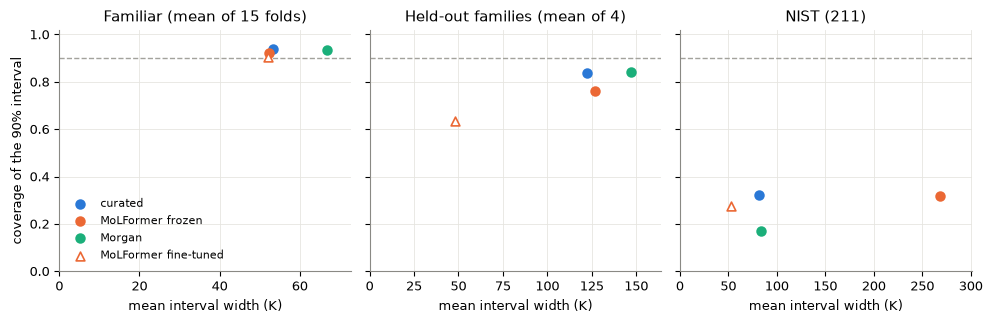

In [21]:
cov = pd.read_csv(f"{U}/coverage.csv")
METHODS = {"curated_frozen": ("curated", "o", COLORS["curated"], "full"),
           "molformer_frozen": ("MoLFormer frozen", "o", COLORS["molformer"], "full"),
           "morgan_frozen": ("Morgan", "o", COLORS["morgan"], "full"),
           "molformer_finetuned_ensemble": ("MoLFormer fine-tuned", "^", COLORS["molformer"], "none")}
primary = cov[(cov["group"] == "all") & cov["variant"].isin(["cvplus", "split"]) & cov["method"].isin(METHODS)]
summ = primary.groupby(["regime", "method"])[["coverage", "width"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
for ax, (regime, title) in zip(axes, [("familiar", "Familiar (mean of 15 folds)"), ("holdout", "Held-out families (mean of 4)"),
                                      ("nist", "NIST (211)")]):
    for m, (label, marker, color, fill) in METHODS.items():
        c, w = summ.loc[(regime, m)]
        ax.scatter(w, c, s=40, marker=marker, color=color, facecolors=color if fill == "full" else "white",
                   linewidths=1.2, label=label, zorder=3)
    ax.axhline(0.9, color=GREY, ls="--", lw=1)
    ax.set(title=title, xlabel="mean interval width (K)")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.08)
axes[0].set(ylabel="coverage of the 90% interval", ylim=(0, 1.02))
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_interval_coverage.png", dpi=150)
plt.show()

wide = primary.groupby(["regime", "method"]).agg(coverage=("coverage", "mean"), coverage_sd=("coverage", "std"),
                                                 width=("width", "mean")).round(3)
display(titled(wide.rename(index={m: v[0] for m, v in METHODS.items()}), "90% prediction intervals: coverage (share of test molecules inside) and mean width (K)"))
per = cov[(cov["regime"] != "familiar") & cov["variant"].isin(["cvplus", "split"]) & cov["method"].isin(METHODS)]
per = per[((per["regime"] == "holdout") & (per["group"] == "all")) | (per["regime"] == "nist")]
per = per.assign(group=np.where(per["regime"] == "holdout", per["task"], per["group"]))   # holdout: one family per task
titled(per.pivot_table(index=["regime", "group"], columns="method", values="coverage").rename(
    columns={m: v[0] for m, v in METHODS.items()}).round(3).join(
    per.groupby(["regime", "group"])["n"].first()), "90% prediction intervals: coverage per held-out family and NIST subgroup (n = test molecules)")

- **Familiar chemistry:** every method reaches the 90% target. CV+ gives 0.921–0.940; the fine-tuned split-conformal intervals give 0.905 but vary about three times more between folds (SD 0.053 vs 0.017–0.020), because they rest on ~75 calibration molecules.
- **Held-out families:** all fall short. Curated 0.835 and Morgan 0.839 come closest, at widths of 122 and 147 K; the fine-tuned intervals are narrow (48 K) and cover only 0.634. Alcohols/phenols are under-covered by every method (0.088–0.459).
- **NIST:** coverage collapses to 0.171–0.322. Frozen MoLFormer covers only 0.318 despite a 268 K mean width, because its intervals are centred on wrong predictions; Morgan covers none of the 87 ring compounds (0.000).

**One width per model hides the families.** Familiar-chemistry errors differ by family, so a single interval width is too wide for some and too narrow for others. Left: one width per model (CV+, and split conformal for the fine-tuned model). Right: Mondrian CV+, calibrated per family. The family "other" has about one test molecule per fold and is left out.

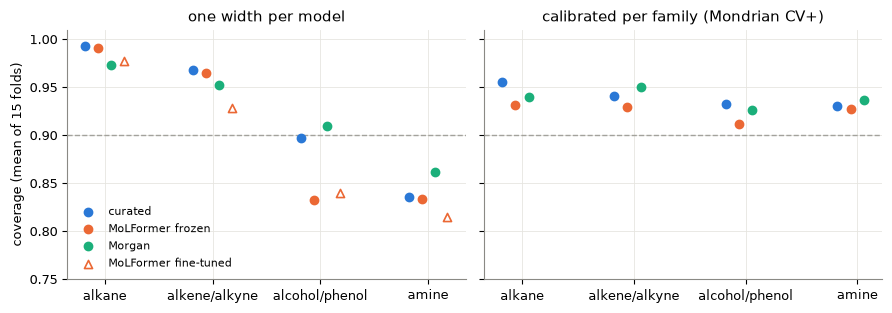

test molecules per fold: {'alcohol/phenol': 70.2, 'alkane': 77.6, 'alkene/alkyne': 73.2, 'amine': 28.4}


In [22]:
fc = cov[(cov["regime"] == "familiar") & ~cov["group"].isin(["all", "other"])]
FAMS = ["alkane", "alkene/alkyne", "alcohol/phenol", "amine"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
panels = [("one width per model", {"curated_frozen": "cvplus", "molformer_frozen": "cvplus", "morgan_frozen": "cvplus",
                                   "molformer_finetuned_ensemble": "split"}),
          ("calibrated per family (Mondrian CV+)", {"curated_frozen": "cvplus_mondrian", "molformer_frozen": "cvplus_mondrian",
                                                   "morgan_frozen": "cvplus_mondrian"})]
for ax, (title, which) in zip(axes, panels):
    for k, (m, variant) in enumerate(which.items()):
        label, marker, color, fill = METHODS[m]
        d = fc[(fc["method"] == m) & (fc["variant"] == variant)].groupby("group")["coverage"].mean().loc[FAMS]
        ax.scatter(np.arange(4) + (k - 1.5) * 0.12, d, marker=marker, s=34, color=color,
                   facecolors=color if fill == "full" else "white", linewidths=1.2, label=label, zorder=3)
    ax.axhline(0.9, color=GREY, ls="--", lw=1)
    ax.set_xticks(range(4), FAMS)
    ax.set(title=title, ylim=(0.75, 1.01))
axes[0].set_ylabel("coverage (mean of 15 folds)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_coverage_by_family.png", dpi=150)
plt.show()
fam_tab = fc[fc["method"].isin(METHODS)].groupby(["method", "variant", "group"])[["coverage", "width"]].mean().unstack("group")
display(titled(fam_tab.round(3).rename(index={m: v[0] for m, v in METHODS.items()}), "Familiar chemistry, 90% intervals per family: coverage and mean width (K), mean over 15 folds"))
print("test molecules per fold:", fc.groupby("group")["n"].mean().round(1).to_dict())

- **One width per model over-covers alkanes and under-covers amines:** alkanes 0.973–0.993, amines 0.815–0.862 across the four methods.
- **Per-family calibration fixes it** for the frozen models (every family 0.912–0.955), by making the intervals honest rather than uniform: amine widths grow from 58–72 K to 111–138 K, alkane widths shrink from 50–63 K to 25–41 K.
- A model used to rank candidates should therefore report family-calibrated intervals; the fine-tuned model's calibration half is too small to split this way.

**Does a model know which of its predictions are bad?** Each method's per-molecule uncertainty is the disagreement of its three inner models (frozen) or three seeds (fine-tuned). A model-free baseline is the **distance to the training set**: 1 − the highest Tanimoto similarity of the molecule's Morgan counts to any training molecule. The table gives the Spearman rank correlation of each score with the absolute error (familiar: mean over folds). The figure shows what the ranking is worth in familiar chemistry: the MAE of the x% most confident predictions, against random order and the oracle that sorts by the true error.

score,distance,model
method,,
curated,0.03,0.34
MoLFormer frozen,0.11,0.26
Morgan,0.18,0.33
MoLFormer fine-tuned,0.05,0.19


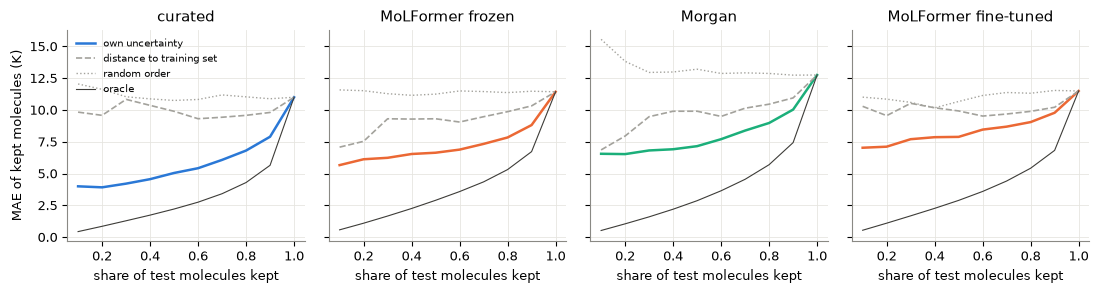

In [23]:
sp = pd.read_csv(f"{U}/spearman.csv")
pooled = sp[sp["scope"] == "all"].groupby(["regime", "method", "score"])["spearman"].mean().unstack("score")
within = sp[(sp["regime"] == "familiar") & (sp["scope"] != "all")].groupby(["method", "score"])["spearman"].mean().unstack()
pooled = pooled.loc[[i for i in pooled.index if i[1] != "molformer_finetuned_seed0"]]
display(titled(pooled.rename(index={m: v[0] for m, v in METHODS.items()}).round(2), "Spearman correlation of each uncertainty score with the absolute error"))
display(titled(within.loc[list(METHODS)].rename(index={m: v[0] for m, v in METHODS.items()}).round(2), "Familiar chemistry: Spearman correlation within each family, mean over families and folds"))

ret = pd.read_csv(f"{U}/retention.csv").groupby(["method", "score", "fraction"])["mae"].mean()
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
for ax, (m, (label, marker, color, fill)) in zip(axes, METHODS.items()):
    r = ret.loc[m]
    ax.plot(r.loc["model"].index, r.loc["model"], color=color, lw=1.8, label="own uncertainty")
    ax.plot(r.loc["distance"].index, r.loc["distance"], color=GREY, lw=1.2, ls="--", label="distance to training set")
    ax.plot(r.loc["random"].index, r.loc["random"], color=GREY, lw=1, ls=":", label="random order")
    ax.plot(r.loc["oracle"].index, r.loc["oracle"], color="#3d3c38", lw=0.8, label="oracle")
    ax.set(title=label, xlabel="share of test molecules kept")
axes[0].set_ylabel("MAE of kept molecules (K)")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_retention.png", dpi=150)
plt.show()
titled(ret.unstack("fraction")[[0.1, 0.2, 0.5, 1.0]].loc[list(METHODS)].round(2), "Familiar chemistry: test MAE (K) of the most confident fraction of predictions (columns: fraction kept)")

- **In familiar chemistry, each model's own uncertainty ranks its errors better than distance to the training set:** Spearman 0.27–0.43 against 0.10–0.27 pooled, and 0.19–0.34 against 0.03–0.18 within families. The fine-tuned seed spread is the weakest model score (0.27).
- **That ranking is useful:** keeping the curated model's most confident 50% of molecules lowers MAE from 11.00 to 5.04 K (the oracle reaches 2.21 K); for frozen MoLFormer 11.43 → 6.64 K, Morgan 12.75 → 7.15 K, fine-tuned 11.49 → 7.88 K.
- **Under shift the picture changes:** on NIST, distance to the training set ranks errors as well as or better than the models' own uncertainty for three of four methods (Morgan 0.71 vs 0.37, curated 0.46 vs 0.26, fine-tuned 0.42 vs 0.32; frozen MoLFormer 0.44 vs 0.54). On held-out families every score is weak (0.02–0.31).

## 11. Error analysis (exploratory): where do the errors come from?

Everything in this section was chosen after the results above were known, so it is **exploratory**: it describes where the errors are and suggests explanations, but it tests nothing and adds nothing to H1–H5. It uses the saved predictions of four models: the best frozen pipelines for curated descriptors, Morgan counts and MoLFormer, and the fine-tuned MoLFormer (canonical SMILES, its absolute error averaged over its 3 seeds). In familiar chemistry each molecule is a test molecule once per repeat, so its error is averaged over the 3 repeats.

Each mean absolute error (MAE) comes with a 95% interval from 2,000 bootstrap resamples of **structure groups**, which keeps stereoisomers together, as in the splits. A bin's difference to curated is resampled on the same draws. The molecular attributes are computed by RDKit from the model SMILES:
- **Hydrogen-bond donors and acceptors** (Lipinski's counts).
- **Hard region:** polar surface area ≥ 40 Å² or ≥ 14 rotatable bonds, PubChem values. This is the region with the largest errors in the project's first error analysis (`features.in_hard_region`, used for the targeted NIST lookups).
- **Small polyols:** at least 2 hydroxyl groups and at most 8 heavy atoms, such as ethylene glycol: the blind spot the Bayesian optimisation part found.
- **Distance to the training set:** 1 − the highest count-Tanimoto similarity to any training molecule of the task (section 10), in fifths (quintiles) per regime.

The pooled MAEs reproduce sections 4 and 7:

In [24]:
EA = f"{R}/error_analysis"
ea_bins = pd.read_csv(f"{EA}/bins.csv")
EA_METHODS = {"curated": ("Curated descriptors", "o", COLORS["curated"], True),
              "morgan": ("Morgan counts", "o", COLORS["morgan"], True),
              "molformer_frozen": ("MoLFormer (frozen)", "o", COLORS["molformer"], True),
              "molformer_finetuned": ("MoLFormer (fine-tuned)", "^", COLORS["molformer"], False)}
titled(ea_bins.query("attribute == 'all'").set_index("method")[["n", "n_groups", "mae", "ci_low", "ci_high"]].round(2), "Familiar chemistry: pooled test MAE (K) with 95% interval (structure-group bootstrap)")

,n,n_groups,mae,ci_low,ci_high
method,,,,,
curated,1250,1181,11.00,9.81,12.24
morgan,1250,1181,12.75,11.46,14.24
molformer_frozen,1250,1181,11.43,10.31,12.59
molformer_finetuned,1250,1181,13.70,12.55,14.90


**Familiar chemistry by molecular attribute.** Dots are MAEs, bars their 95% intervals. The family "other" (3 molecules) is left out of the figure.

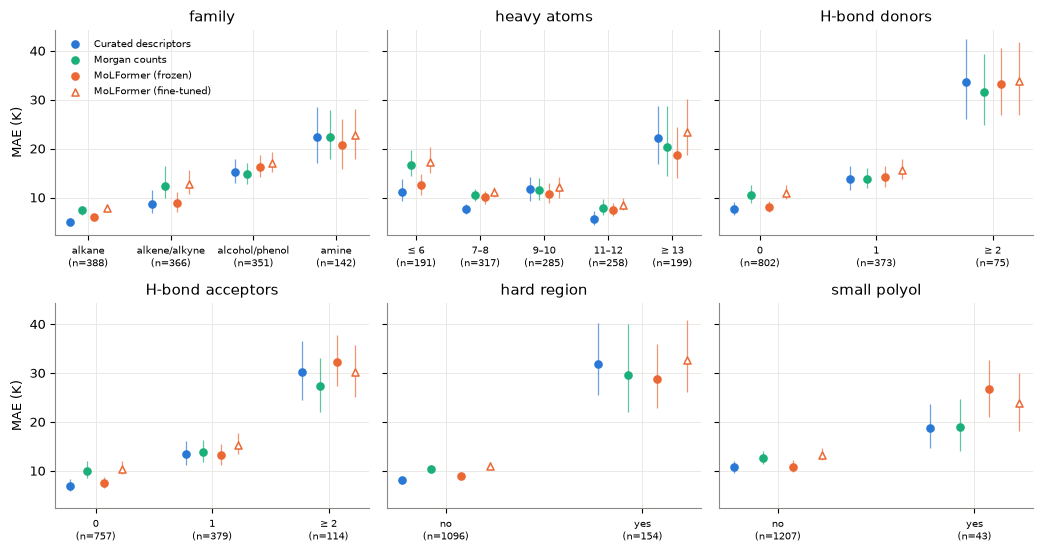

In [25]:
PANELS = [("family", "family", ["alkane", "alkene/alkyne", "alcohol/phenol", "amine"]),
          ("heavy_atoms", "heavy atoms", ["≤ 6", "7–8", "9–10", "11–12", "≥ 13"]),
          ("hbd", "H-bond donors", ["0", "1", "≥ 2"]), ("hba", "H-bond acceptors", ["0", "1", "≥ 2"]),
          ("hard_region", "hard region", ["no", "yes"]), ("small_polyol", "small polyol", ["no", "yes"])]
fam_bins = ea_bins[ea_bins["regime"] == "familiar"]
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6), sharey=True)
for ax, (attr, title, order) in zip(axes.flat, PANELS):
    d = fam_bins[fam_bins["attribute"] == attr].set_index(["bin", "method"])
    for k, (m, (label, marker, color, filled)) in enumerate(EA_METHODS.items()):
        x = np.arange(len(order)) + (k - 1.5) * 0.15
        r = d.xs(m, level="method").loc[order]
        ax.errorbar(x, r["mae"], yerr=[r["mae"] - r["ci_low"], r["ci_high"] - r["mae"]], fmt="none", ecolor=color,
                    elinewidth=0.9, alpha=0.7)
        ax.scatter(x, r["mae"], marker=marker, s=26, color=color, facecolors=color if filled else "white",
                   linewidths=1.1, label=label, zorder=3)
    n = d.xs("curated", level="method").loc[order, "n"]
    ax.set_xticks(range(len(order)), [f"{b}\n(n={c})" for b, c in zip(order, n)], fontsize=7.5)
    ax.set_title(title)
for ax in axes[:, 0]:
    ax.set_ylabel("MAE (K)")
axes[0, 0].legend(frameon=False, fontsize=7.5, loc="upper left")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_errors_by_attribute.png", dpi=150)
plt.show()

def diff_cell(r):
    return f"{r['diff']:+.1f} [{r['diff_ci_low']:+.1f}, {r['diff_ci_high']:+.1f}]"

def ea_table(rows, keys):
    t = rows.assign(mae_ci=rows.apply(lambda r: f"{r['mae']:.1f} [{r['ci_low']:.1f}, {r['ci_high']:.1f}]", axis=1),
                    diff_ci=rows.apply(diff_cell, axis=1))
    mae = t.pivot_table(index=keys, columns="method", values="mae_ci", aggfunc="first", sort=False)[list(EA_METHODS)]
    diff = t[t["method"] != "curated"].pivot_table(index=keys, columns="method", values="diff_ci", aggfunc="first",
                                                   sort=False)[list(EA_METHODS)[1:]]
    n = t[t["method"] == "curated"].set_index(keys)["n"]
    return pd.concat({"MAE [95% interval] (K)": mae, "difference to curated [95% interval] (K)": diff}, axis=1).join(
        n.rename(("", "n")))

titled(ea_table(fam_bins[fam_bins["attribute"].isin([p[0] for p in PANELS])], ["attribute", "bin"]), "Familiar chemistry by attribute: test MAE and difference to curated (K), 95% intervals")

- **The hard molecules are hard for every representation.** In the hard region the four MAEs are 28.8–32.6 K, against 8.1–11.0 K outside it (154 vs 1,096 molecules); with ≥ 2 hydrogen-bond donors they are 31.5–33.9 K, against 7.6–10.9 K with none. Within each of these bins the intervals of the four models overlap, so the choice of representation matters little where the errors are largest.
- **The curated descriptors' edge is in simple molecules.** Every other model is worse than curated on alkanes (Morgan +2.4, frozen MoLFormer +1.1, fine-tuned +3.0 K, all intervals above zero). Morgan and the fine-tuned model are also worse on molecules without hydrogen-bond donors (+2.9 and +3.3 K), but frozen MoLFormer is not (+0.5 K [−0.1, +1.1]). For large molecules (≥ 13 heavy atoms) frozen MoLFormer is better (−3.4 K [−6.1, −0.8]).
- **Small polyols are frozen MoLFormer's clearest weak spot:** 26.7 K against 18.7 K for curated (+7.9 K [+2.9, +12.6]). The fine-tuned model is also worse there (+5.1 K [+1.0, +9.5]), while Morgan is level (+0.2 K). That is 43 molecules, picked after the fact.
- **Fine-tuning's deficit is largest in the smallest molecules:** +6.0 K [+4.8, +7.3] against curated with ≤ 6 heavy atoms.

**Error against distance to the training set**, in quintiles of distance within each regime. The x-axis labels give each quintile's observed range; the three panels have different scales.

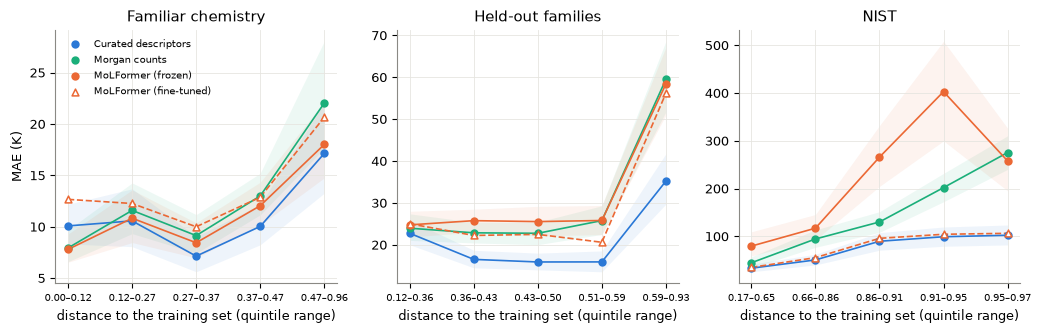

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
dist = ea_bins[ea_bins["attribute"] == "train_distance"]
for ax, (regime, title) in zip(axes, [("familiar", "Familiar chemistry"), ("holdout", "Held-out families"),
                                      ("nist", "NIST")]):
    d = dist[dist["regime"] == regime]
    order = list(dict.fromkeys(d["bin"]))
    for m, (label, marker, color, filled) in EA_METHODS.items():
        r = d[d["method"] == m].set_index("bin").loc[order]
        x = np.arange(len(order))
        ax.fill_between(x, r["ci_low"], r["ci_high"], color=color, alpha=0.08 if filled else 0, lw=0)
        ax.plot(x, r["mae"], color=color, lw=1.2, ls="-" if filled else "--")
        ax.scatter(x, r["mae"], marker=marker, s=24, color=color, facecolors=color if filled else "white",
                   linewidths=1.1, label=label, zorder=3)
    ax.set_xticks(range(len(order)), [b.split(": ")[1] for b in order], fontsize=7.5)
    ax.set(title=title, xlabel="distance to the training set (quintile range)")
axes[0].set_ylabel("MAE (K)")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper left")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_errors_by_distance.png", dpi=150)
plt.show()
titled(ea_table(dist, ["regime", "bin"]), "By distance to the training set: test MAE and difference to curated (K), 95% intervals")

- **Error grows with distance for every model, but not equally.** On familiar chemistry, curated rises from 10.1 K in the nearest quintile to 17.1 K in the farthest, and frozen MoLFormer from 7.8 to 18.0 K. In the nearest quintile (distance ≤ 0.12, close analogues of training molecules), Morgan and frozen MoLFormer beat curated (−2.1 K [−3.7, −0.7] and −2.3 K [−3.8, −0.9]).
- **Held-out families:** curated stays near 16 K through the middle three quintiles (16.5, 15.9, 15.9 K), while the others sit at 20.6–25.8 K. All four jump in the farthest quintile: curated to 35.2 K, the others to 56.2–59.5 K.
- **NIST:** frozen MoLFormer's gap to curated grows from +46.2 K in the nearest quintile to +303.7 K in the fourth, and Morgan's from +11.4 to +173.1 K in the farthest. The fine-tuned model tracks curated in every quintile (+1.6 to +6.1 K, all intervals including zero).
- **So distance flags risk for every model, while the representation sets how fast error grows with it.** The curated descriptors degrade slowest, matched on NIST by the fine-tuned model.

**NIST labels from one measurement or several.** Single-measurement labels have no second source to check them against, so they may be noisier. MAE (K) by subgroup:

In [27]:
cells = pd.read_csv(f"{EA}/nist_cells.csv")
cells["single_measurement"] = cells["single_measurement"].map({True: "single", False: "repeated"})
titled(ea_table(cells, ["subgroup", "single_measurement"]), "NIST by label source: test MAE and difference to curated (K), 95% intervals")

- **Single-measurement labels don't explain the NIST errors.** Curated's MAE is higher for single labels in "other" (51.8 vs 34.7 K) but lower in the halogenated (99.2 vs 111.0 K) and ring-containing subgroups (75.3 vs 82.8 K), and each pair of intervals overlaps.
- **The representation gaps are the same in both halves.** For example, frozen MoLFormer is +318.2 K (repeated) and +306.2 K (single) worse than curated on ring-containing compounds, so the NIST conclusions don't rest on the single-measurement labels.

**The 20 largest disagreements.** The familiar-chemistry molecules where frozen MoLFormer's and the curated descriptors' predictions (each the mean over 3 repeats) differ most. The best curated pipeline is XGBoost but MoLFormer's is Ridge, and tree ensembles cannot predict outside the range of their training targets. The curated + Ridge prediction is therefore shown too, to separate the regressor from the representation.

literature boiling points: 111.7–1167.9 K; central 95%: 305.4–683.2 K


,name,family,measured (K),error curated + XGBoost (K),error curated + Ridge (K),error MoLFormer + Ridge (K),closest,outside central 95%,heavy atoms,hard region,small polyol
0,"2,5,8,11-Tetraoxatridecan-13-ol",alcohol/phenol,557.0,19.6,102.0,92.7,curated + XGBoost,False,14,True,False
1,"3,6,9,12,15,18-Hexaoxaicosane-1,20-diol",alcohol/phenol,515.6,90.9,95.4,15.6,MoLFormer,False,22,True,False
2,1-Tetracosanol,alcohol/phenol,675.0,105.0,21.2,14.0,MoLFormer,False,25,True,False
3,Lycopene,alkene/alkyne,1167.9,409.6,375.1,329.1,MoLFormer,True,40,True,False
4,Diethylenetriamine,amine,479.6,75.3,49.6,8.9,MoLFormer,False,7,True,False
5,Squalene,alkene/alkyne,694.4,88.1,130.7,163.1,curated + XGBoost,True,30,True,False
6,Ethylene,alkene/alkyne,169.4,40.5,19.0,32.6,curated + Ridge,True,2,False,False
7,Pentaethylenehexamine,amine,653.2,66.9,76.0,15.1,MoLFormer,False,16,True,False
8,2-Isopropoxyethanol,alcohol/phenol,414.8,5.5,14.9,60.3,curated + XGBoost,False,7,False,False
9,"3,6-Nonadien-1-ol",alcohol/phenol,506.0,73.4,10.3,7.8,MoLFormer,False,10,False,False


MoLFormer closer than curated + XGBoost: 16 of 20; curated + Ridge closer than MoLFormer: 9 of 20
closest model: {'MoLFormer': 10, 'curated + Ridge': 7, 'curated + XGBoost': 3}
outside the central 95%: 6 | hard region: 13 | small polyols: 0


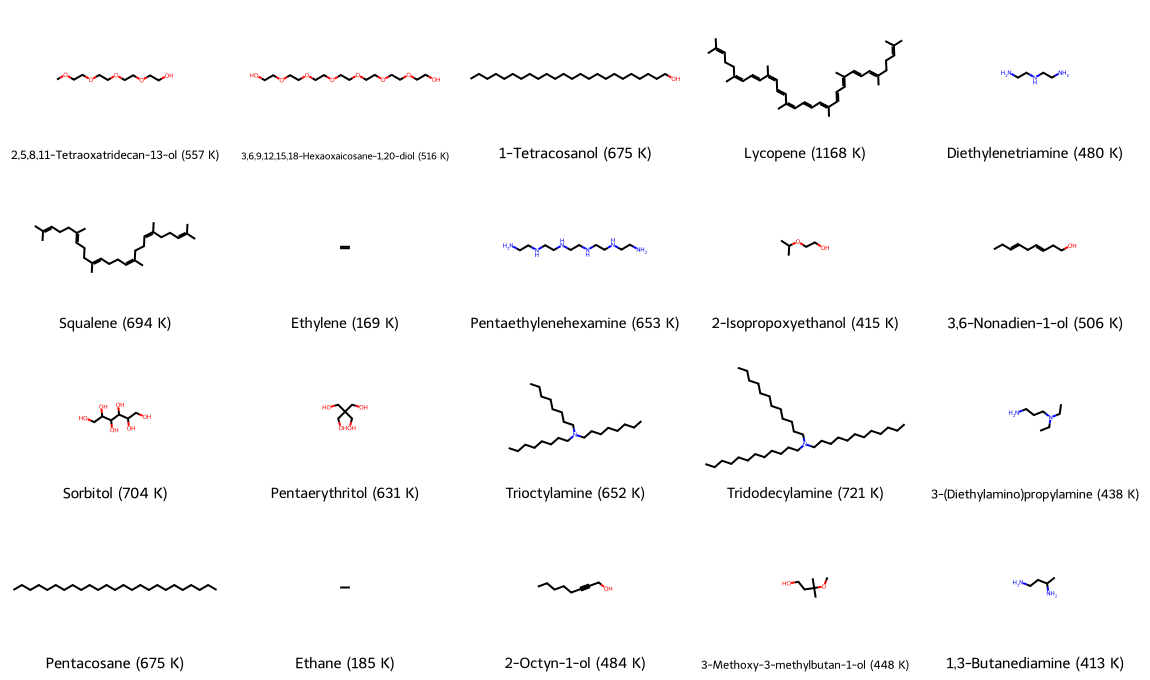

In [28]:
dis = pd.read_csv(f"{EA}/disagreements.csv")
y_lit = splits["boiling_point_kelvin"]
print(f"literature boiling points: {y_lit.min():.1f}–{y_lit.max():.1f} K; central 95%: "
      f"{y_lit.quantile(0.025):.1f}–{y_lit.quantile(0.975):.1f} K")
dis["outside central 95%"] = (dis["y_true"] < y_lit.quantile(0.025)) | (dis["y_true"] > y_lit.quantile(0.975))
dis["closest"] = dis[["err_curated", "err_curated_ridge", "err_molformer_frozen"]].idxmin(axis=1).map(
    {"err_curated": "curated + XGBoost", "err_curated_ridge": "curated + Ridge", "err_molformer_frozen": "MoLFormer"})
cols = {"name": "name", "group": "family", "y_true": "measured (K)", "err_curated": "error curated + XGBoost (K)",
        "err_curated_ridge": "error curated + Ridge (K)", "err_molformer_frozen": "error MoLFormer + Ridge (K)",
        "closest": "closest", "outside central 95%": "outside central 95%", "heavy_atoms": "heavy atoms",
        "hard_region": "hard region", "small_polyol": "small polyol"}
display(titled(dis[list(cols)].rename(columns=cols).round(1), "The 20 largest MoLFormer–curated disagreements in familiar chemistry (errors are absolute, K)"))
print("MoLFormer closer than curated + XGBoost:", int((dis["err_molformer_frozen"] < dis["err_curated"]).sum()), "of 20;",
      "curated + Ridge closer than MoLFormer:", int((dis["err_curated_ridge"] < dis["err_molformer_frozen"]).sum()), "of 20")
print("closest model:", dis["closest"].value_counts().to_dict())
print("outside the central 95%:", int(dis["outside central 95%"].sum()), "| hard region:", int(dis["hard_region"].sum()),
      "| small polyols:", int(dis["small_polyol"].sum()))

from rdkit.Chem import Draw
img = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in dis["smiles"]], molsPerRow=5, subImgSize=(230, 170),
                           legends=[f"{n} ({y:.0f} K)" for n, y in zip(dis["name"], dis["y_true"])])
with open(f"{IMG}/representation_disagreements.png", "wb") as fh:   # Jupyter: an IPython PNG image
    fh.write(img.data if hasattr(img, "data") else img._repr_png_())
display(img)

- **About half of the disagreement is the regressor, not the representation.** MoLFormer + Ridge is closer than curated + XGBoost in 16 of 20 cases, but curated + Ridge is closer than MoLFormer in 9 of 20; the closest model is MoLFormer 10 times, curated + Ridge 7 and curated + XGBoost 3. Trees cannot extrapolate: 1-tetracosanol (curated + XGBoost 105.0 K error, curated + Ridge 21.2 K), trioctylamine (84.6 vs 12.9 K), ethane (51.5 vs 14.7 K).
- **The disagreements are extreme molecules:** 13 of the 20 are in the hard region and 6 lie outside the central 95% of boiling points (305.4–683.2 K). They are long chains, polyethers, polyamines, polyols such as sorbitol and pentaerythritol, and terpenes. None is a small polyol.
- **Lycopene has the highest label in the set (1,167.9 K; range 111.7–1,167.9 K), and all three models in the table miss it by more than 300 K** (329.1–409.6 K).

**Does the spelling of a SMILES change frozen MoLFormer's predictions?** Section 3 showed the frozen embeddings move with the spelling. Here each familiar fold's MoLFormer + Ridge model, refitted with its saved layer and alpha (reproducing the saved predictions to within 10⁻⁶ K), predicts each test molecule from its canonical SMILES and from each of the same 10 randomised spellings used for the cache. The curated descriptors and Morgan counts are computed from the molecular graph, so the spelling cannot change them. The fine-tuned model was trained on random spellings; its spelling-averaged MAE is in section 7.

In [29]:
sp = pd.read_csv(f"{EA}/spelling.csv")
cols_sp = [c for c in sp if c.startswith("pred_spelling_")]
err = lambda p: (p - sp["y_true"]).abs()
per_spelling = pd.Series({c: err(sp[c]).mean() for c in cols_sp})
rows = [("MAE, canonical SMILES (as in every result above)", err(sp["pred_canonical"]).mean()),
        ("MAE, one random spelling (mean over the 10)", per_spelling.mean()),
        ("MAE, one random spelling: lowest / highest of the 10", f"{per_spelling.min():.2f} / {per_spelling.max():.2f}"),
        ("MAE, mean prediction over the 10 spellings", err(sp["spelling_mean"]).mean()),
        ("SD of a molecule's 10 predictions: median (K)", sp["spelling_sd"].median()),
        ("SD of a molecule's 10 predictions: interquartile range (K)",
         f"{sp['spelling_sd'].quantile(0.25):.2f}–{sp['spelling_sd'].quantile(0.75):.2f}"),
        ("share of molecule × fold predictions with SD > 1.0 K", np.mean(sp["spelling_sd"] > 1.0)),
        ("share with SD = 0 (one spelling only, e.g. methane)", np.mean(sp["spelling_sd"] == 0)),
        ("Spearman: SD vs canonical absolute error", sp["spelling_sd"].corr(err(sp["pred_canonical"]), method="spearman")),
        ("molecule × fold predictions", len(sp))]
titled(pd.DataFrame(rows, columns=["quantity", "value"]).set_index("quantity").map(
    lambda v: f"{v:.3f}" if isinstance(v, float) and v < 1 else (f"{v:.2f}" if isinstance(v, float) else v)), "Frozen MoLFormer + Ridge, familiar chemistry: canonical against randomised SMILES")

,value
quantity,
"MAE, canonical SMILES (as in every result above)",11.43
"MAE, one random spelling (mean over the 10)",21.07
"MAE, one random spelling: lowest / highest of the 10",20.50 / 21.59
"MAE, mean prediction over the 10 spellings",17.26
SD of a molecule's 10 predictions: median (K),14.32
SD of a molecule's 10 predictions: interquartile range (K),10.10–19.31
share of molecule × fold predictions with SD > 1.0 K,0.995
"share with SD = 0 (one spelling only, e.g. methane)",0.002
Spearman: SD vs canonical absolute error,0.151


- **Frozen MoLFormer depends on the canonical spelling.** Its MAE is 11.43 K from canonical SMILES and 21.07 K from one random spelling of the same molecules (×1.84; 20.50–21.59 K across the 10 spellings).
- **The spread is large for almost every molecule:** the median standard deviation of a molecule's 10 predictions is 14.32 K (interquartile range 10.10–19.31 K), and 0.995 of predictions have a standard deviation above the 1.0 K minimum meaningful difference. That spread is larger than the C1 difference between MoLFormer and curated (+0.43 K, section 9).
- **Averaging over spellings doesn't recover the canonical accuracy (17.26 K),** because the Ridge models were fitted on canonical embeddings. The spread only weakly tracks the error (Spearman 0.151), so it is a poor uncertainty signal.
- **In practice,** the frozen result holds only for canonical SMILES from the same RDKit canonicalisation. The fine-tuned model was trained on random spellings, but its per-spelling predictions were not saved, so its sensitivity is not measured here.

## 12. Combining representations (exploratory): does MoLFormer add to the descriptors?

Sections 4–9 compare representations head to head. This section asks the study's question a second way: once the descriptors are in the model, does MoLFormer still add information? It was planned after the results above, so it is **exploratory**: raw p-values, no Holm correction, and it changes none of C1–C5.

Two ways of combining, both learned only from training data:
- **Stacking** (stacked regression, Breiman 1996, *Machine Learning* 24): a weighted average of saved pipelines' predictions. The weights are non-negative and sum to 1. In each task they are fitted on the pipelines' **out-of-fold** training predictions from the inner cross-validation, so no test molecule is used. By default the weights minimise squared error; the "absolute-error weights" variants minimise absolute error instead.
  - **S1:** best curated (XGBoost) + best MoLFormer (Ridge). The main variant.
  - **S0:** curated Ridge + curated XGBoost. A control: any blend of two decent models can beat either one by averaging out noise, so MoLFormer adds information only if S1 also beats S0.
  - **S1m:** best curated + best Morgan. A second control: a second view of the molecule that wasn't pretrained.
  - **S2:** all six frozen pipelines (3 representations × Ridge/XGBoost).
  - **S1 and S0 with absolute-error weights** (sensitivity). S0's absolute-error version was added after seeing S0's results (explained below).
  - **Equal-weight average** of the two best pipelines, with no fitting. It was computed while planning, so it is shown for scale only.
- **Concatenated features with Ridge:** the 43 descriptors joined to one MoLFormer layer. Each block is standardised and divided by √(its column count), so the 768 embedding columns don't outweigh the 43 descriptors in the Ridge penalty. The layer and penalty are tuned in the inner cross-validation, as for MoLFormer + Ridge.

**Rule (fixed before running, but after seeing the equal-weight average):** MoLFormer *adds to curated* in a regime only if S1 − best curated ≤ −1.0 K with a 95% interval that excludes 0, and S1 also beats S0. The familiar-chemistry interval is estimate ± t(0.975, 14) × SE from the corrected resampled t-test.

**Caveats.** The out-of-fold predictions come from models trained on about two thirds of each training set, with hyperparameters chosen on the same folds, so they are slightly optimistic. The NIST weights are learned on literature molecules, where MoLFormer looks good, so they cannot anticipate the shift to new elements and rings.

**First, why there is no separate "extrapolating regressor" for the descriptors.** Section 11 found curated + XGBoost far off on some of the largest disagreements because trees cannot predict beyond their training range. A check of how much that costs on average, using the saved predictions:

In [30]:
C = f"{R}/combined"
hold = splits["holdout_family"].fillna("")
def train_y(regime, task):
    if regime == "familiar":
        r, k = int(task[1]), int(task[3])
        return splits.loc[splits[f"fold_r{r}"] != k, "boiling_point_kelvin"]
    if regime == "holdout":
        return splits.loc[(hold != "") & (hold != task), "boiling_point_kelvin"]
    return splits["boiling_point_kelvin"]
cur = preds[preds["representation"] == "curated"].copy()
bounds = {(g, t): train_y(g, t).quantile([0, 0.02, 0.98, 1]).to_numpy() for g, t in cur.groupby(["regime", "task"]).groups}
b = np.array([bounds[(g, t)] for g, t in zip(cur["regime"], cur["task"])])
cur["outside range"] = (cur["y_true"] < b[:, 0]) | (cur["y_true"] > b[:, 3])
cur["band"] = np.select([cur["y_true"] < b[:, 1], cur["y_true"] > b[:, 2]], ["bottom 2%", "top 2%"], "middle 96%")
one = cur[cur["regressor"] == "xgboost"]
display(titled(pd.DataFrame({"test rows": one.groupby("regime").size(),
                      "outside the training range": one.groupby("regime")["outside range"].sum(),
                      "in the top or bottom 2% of the training range": one.groupby("regime")["band"].apply(lambda s: (s != "middle 96%").sum())}), "Test molecules near or beyond their training set's range of boiling points (number of molecules)"))
fam = cur[cur["regime"] == "familiar"]
tail = fam.pivot_table(index="band", columns="regressor", values="abs_err", aggfunc="mean").rename(columns=REG)
tail.insert(0, "rows", fam[fam["regressor"] == "xgboost"].groupby("band").size())
tail.loc["share of total absolute error in the two tails"] = [np.nan] + [
    fam[(fam["regressor"] == g) & (fam["band"] != "middle 96%")]["abs_err"].sum() / fam[fam["regressor"] == g]["abs_err"].sum()
    for g in ("ridge", "xgboost")]
titled(tail.round(3), "Familiar chemistry, curated descriptors: test MAE (K) by position in the training fold's boiling-point range")

,test rows,outside the training range,in the top or bottom 2% of the training range
regime,,,
familiar,3750,11,161
holdout,1247,2,64
nist,211,0,26


regressor,rows,Ridge,XGBoost
band,,,
bottom 2%,80,21.081,20.533
middle 96%,3589,13.934,10.131
top 2%,81,35.894,39.930
share of total absolute error in the two tails,,0.084,0.118


- **Few test molecules lie outside the training range:** 11 of 3,750 in familiar chemistry, 2 of 1,247 in held-out families and 0 of 211 on NIST.
- **In familiar chemistry, XGBoost loses to Ridge only at the top of the range:** 39.93 vs 35.89 K in the top 2% (81 rows), and about level in the bottom 2% (20.53 vs 21.08 K). In the middle 96% XGBoost is far better (10.13 vs 13.93 K).
- **The two tails carry 0.118 of XGBoost's total absolute error.** Matching Ridge on the top 2% would lower the pooled MAE by only (39.93 − 35.89) × 81 / 3,750 ≈ 0.09 K.
- **So the trees' range limit explains some individual large errors (section 11) but little of the average.** No separate extrapolating regressor is tried; S0 below covers a Ridge/XGBoost blend.

**MAE of each pipeline and combination.** Blue: curated descriptors only. Orange: uses MoLFormer. Aqua: uses Morgan counts. Filled circles are single pipelines, open diamonds combinations. The dashed line marks the best curated pipeline. In familiar chemistry the bars are ±1 standard deviation (SD) over the 15 folds; held-out families show the mean over the 4 families, and NIST the pooled MAE. The panels have different scales.

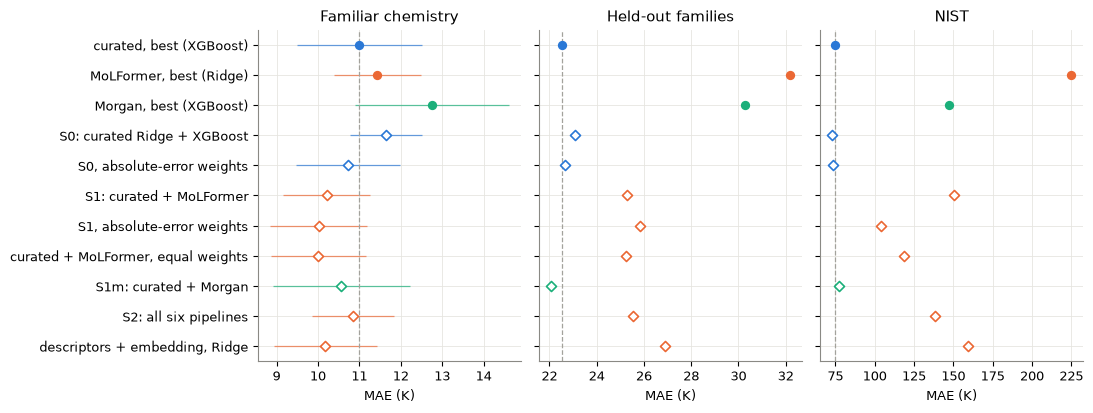

,familiar: MAE ± SD over 15 folds,held-out families: mean of 4,NIST: pooled,NIST: mean of 3 subgroups
"curated, best (XGBoost)",11.00 ± 1.51,22.51,74.68,75.86
"MoLFormer, best (Ridge)",11.43 ± 1.05,32.18,224.81,204.55
"Morgan, best (XGBoost)",12.75 ± 1.86,30.26,147.41,133.02
S0: curated Ridge + XGBoost,11.64 ± 0.87,23.08,72.96,73.09
"S0, absolute-error weights",10.72 ± 1.26,22.66,73.38,74.11
S1: curated + MoLFormer,10.21 ± 1.05,25.28,150.08,134.19
"S1, absolute-error weights",10.01 ± 1.17,25.82,103.95,92.90
"curated + MoLFormer, equal weights",10.01 ± 1.15,25.25,118.47,105.30
S1m: curated + Morgan,10.56 ± 1.66,22.07,77.34,74.65
S2: all six pipelines,10.84 ± 0.99,25.54,138.30,123.21


In [31]:
cm = pd.read_csv(f"{C}/metrics.csv")
ROWS = {"curated_best": ("curated, best (XGBoost)", "curated", True),
        "molformer_best": ("MoLFormer, best (Ridge)", "molformer", True),
        "morgan_best": ("Morgan, best (XGBoost)", "morgan", True),
        "S0": ("S0: curated Ridge + XGBoost", "curated", False),
        "S0_abs": ("S0, absolute-error weights", "curated", False),
        "S1": ("S1: curated + MoLFormer", "molformer", False),
        "S1_abs": ("S1, absolute-error weights", "molformer", False),
        "average": ("curated + MoLFormer, equal weights", "molformer", False),
        "S1m": ("S1m: curated + Morgan", "morgan", False),
        "S2": ("S2: all six pipelines", "molformer", False),
        "concat_ridge": ("descriptors + embedding, Ridge", "molformer", False)}
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharey=True)
ypos = np.arange(len(ROWS))[::-1]
for ax, (regime, title) in zip(axes, [("familiar", "Familiar chemistry"), ("holdout", "Held-out families"), ("nist", "NIST")]):
    m = cm[cm["regime"] == regime].set_index("method")
    for y, (key, (label, rep_, single)) in zip(ypos, ROWS.items()):
        color = COLORS[rep_]
        if regime == "familiar":
            ax.errorbar(m.loc[key, "mae"], y, xerr=m.loc[key, "sd"], fmt="none", ecolor=color, elinewidth=0.9, alpha=0.7)
        ax.scatter(m.loc[key, "mae"], y, marker="o" if single else "D", s=30 if single else 26, color=color,
                   facecolors=color if single else "white", linewidths=1.2, zorder=3)
    ax.axvline(m.loc["curated_best", "mae"], color=GREY, ls="--", lw=0.9)
    ax.set(title=title, xlabel="MAE (K)")
axes[0].set_yticks(ypos, [v[0] for v in ROWS.values()])
fig.tight_layout()
fig.savefig(f"{IMG}/representation_combined.png", dpi=150)
plt.show()

tab = cm.pivot_table(index="method", columns="regime", values=["mae", "sd"])
out = pd.DataFrame({"familiar: MAE ± SD over 15 folds": [f"{tab.loc[k, ('mae', 'familiar')]:.2f} ± {tab.loc[k, ('sd', 'familiar')]:.2f}" for k in ROWS],
                    "held-out families: mean of 4": [round(tab.loc[k, ("mae", "holdout")], 2) for k in ROWS],
                    "NIST: pooled": [round(tab.loc[k, ("mae", "nist")], 2) for k in ROWS],
                    "NIST: mean of 3 subgroups": cm[cm["regime"] == "nist"].set_index("method").loc[list(ROWS), "nist_macro_mae"].round(2).to_numpy()},
                   index=[v[0] for v in ROWS.values()])
titled(out, "Single and combined pipelines: test MAE (K) per regime")

- **Familiar chemistry: every combination that uses MoLFormer is below the best curated pipeline** (11.00 ± 1.51 K): S1 10.21 ± 1.05, S1 with absolute-error weights 10.01 ± 1.17, and descriptors + embedding with Ridge 10.18 ± 1.24 K. The controls gain less: S0 with absolute-error weights 10.72 K and curated + Morgan 10.56 K. S0 with squared-error weights is worse than curated alone (11.64 K).
- **Held-out families: every MoLFormer combination is worse than the curated descriptors alone** (22.51 K). S1 reaches 25.28 K and the concatenated Ridge 26.89 K. Only curated + Morgan improves on curated, slightly (22.07 K).
- **NIST: MoLFormer combinations score 103.95–159.15 K against 74.68 K for curated.** The blend carries part of MoLFormer's own failure (224.81 K) into the prediction. Curated-only blends are slightly better than curated alone (S0 72.96 K, S0 with absolute-error weights 73.38 K).
- **Combining helps where MoLFormer alone is competitive and hurts where it fails.**

**Stacking weights.** The mean weight over tasks, with the lowest and highest in brackets; held-out families have 4 tasks and NIST 1. "Out-of-fold MAE" is the blend's error on the training predictions the weights were fitted to, averaged over tasks. The second table gives the base pipelines' own out-of-fold errors in familiar chemistry, to show why squared-error and absolute-error weights differ.

In [32]:
w = pd.read_csv(f"{C}/weights.csv")
w = w[w["method"] != "average"]
cell = w.groupby(["regime", "method", "pipeline"])["weight"].agg(lambda s: f"{s.mean():.2f} [{s.min():.2f}–{s.max():.2f}]" if len(s) > 1 else f"{s.mean():.2f}")
wt = cell.unstack("pipeline").fillna("")
wt["out-of-fold MAE (K)"] = w.drop_duplicates(["regime", "task", "method"]).groupby(["regime", "method"])["oof_mae"].mean().round(2)
display(titled(wt.loc[[(g, m) for g in ("familiar", "holdout", "nist") for m in ("S0", "S0_abs", "S1", "S1_abs", "S1m", "S2")]], "Stacking weight of each input pipeline: mean [lowest–highest] over tasks; blend's out-of-fold MAE (K)"))

res = pd.concat([pd.read_csv(f"{F}/{g}_cvplus_residuals.csv.gz") for g in ("ridge", "xgboost")])
res = res[res["regime"] == "familiar"].assign(pipeline=lambda r: r["representation"] + " + " + r["regressor"].map(REG))
per = res.groupby(["pipeline", "task"])["residual"].agg(mae=lambda r: r.abs().mean(), rmse=lambda r: np.sqrt((r ** 2).mean()))
titled(per.groupby("pipeline").mean().loc[["curated + Ridge", "curated + XGBoost", "molformer + Ridge", "morgan + XGBoost"]].round(2), "Familiar chemistry: base pipelines' out-of-fold MAE and RMSE (K), mean over 15 tasks")

,mae,rmse
pipeline,,
curated + Ridge,14.41,25.35
curated + XGBoost,11.45,25.86
molformer + Ridge,11.94,24.91
morgan + XGBoost,14.35,30.82


- **In familiar chemistry MoLFormer gets about half the weight:** 0.58 [0.28–0.84] in S1 and 0.45 [0.32–0.56] with absolute-error weights. Morgan gets only 0.18 [0.00–0.45] next to curated (S1m). In S2, MoLFormer + XGBoost and the two Morgan pipelines get at most 0.21 each.
- **The weights cannot see a shift.** On NIST, S1 gives MoLFormer 0.66: the training predictions it was fitted to have an out-of-fold MAE of 10.22 K, while the NIST test MAE is 150.08 K (previous table). On held-out families, the leave-one-family-out inner folds still favour MoLFormer (S1 out-of-fold 23.64 K vs S0 25.82 K) and give it 0.50.
- **Why S0's squared-error weights raise MAE:** curated Ridge and XGBoost have almost the same out-of-fold RMSE (25.35 vs 25.86 K) but very different MAE (14.41 vs 11.45 K). A squared-error fit therefore splits them about evenly (0.53 / 0.47 in familiar chemistry), and the blend's out-of-fold MAE (11.67 K) is above XGBoost's alone. Absolute-error weights give XGBoost 0.76 [0.66–0.81].

**Paired contrasts**, MAE(first) − MAE(second): negative means the first is better. They use the same tests as C1–C3: the corrected resampled t-test over 15 folds for familiar chemistry, and the stratified bootstrap with equal weight per family or subgroup for held-out families and NIST. Each cell is the estimate [95% interval] and the raw p-value; ✓ marks a difference of at least 1.0 K in favour of the first, with the interval below 0. "(abs.)" marks the absolute-error weights.

In [33]:
cc = pd.read_csv(f"{C}/contrasts.csv")
LABEL = {"curated_best": "best curated", "molformer_best": "best MoLFormer", "concat_ridge": "descriptors + embedding (Ridge)",
         "S0_abs": "S0 (abs.)", "S1_abs": "S1 (abs.)", "average": "equal-weight average"}
cc["contrast"] = cc["contrast"].map(lambda c: " − ".join(LABEL.get(x, x) for x in c.split(" - ")))
fmt_p = lambda p: "< 0.0002" if p == 0 else (f"{p:.4f}" if p < 0.001 else f"{p:.3f}")
cc["cell"] = cc.apply(lambda r: f"{r['estimate']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}], p {fmt_p(r['p_raw'])}"
                      + ("  ✓" if r["at_least_1K_better"] else ""), axis=1)
titled(cc.pivot_table(index="contrast", columns="regime", values="cell", aggfunc="first", sort=False)[["familiar", "holdout", "nist"]].rename(
    columns={"familiar": "familiar (15 folds)", "holdout": "held-out families (4)", "nist": "NIST (3 subgroups)"}), "Paired difference in MAE (K), first − second (negative = first better): estimate [95% interval], raw p")

regime,familiar (15 folds),held-out families (4),NIST (3 subgroups)
contrast,,,
S0 − best curated,"+0.65 [-0.65, +1.94], p 0.302","+0.57 [+0.31, +0.82], p < 0.0002","-2.77 [-5.21, -0.27], p 0.028 ✓"
S1 − best curated,"-0.79 [-1.73, +0.15], p 0.095","+2.77 [+1.86, +3.64], p < 0.0002","+58.33 [+41.66, +75.58], p < 0.0002"
S1m − best curated,"-0.44 [-0.73, -0.14], p 0.007","-0.44 [-0.58, -0.30], p < 0.0002","-1.21 [-5.45, +2.91], p 0.582"
S2 − best curated,"-0.15 [-1.77, +1.46], p 0.840","+3.03 [+2.12, +3.93], p < 0.0002","+47.35 [+31.44, +63.61], p < 0.0002"
S1 (abs.) − best curated,"-0.98 [-1.67, -0.29], p 0.009","+3.31 [+2.37, +4.23], p < 0.0002","+17.05 [+4.75, +29.63], p 0.008"
S0 (abs.) − best curated,"-0.28 [-0.79, +0.23], p 0.262","+0.14 [-0.08, +0.36], p 0.203","-1.75 [-2.95, -0.53], p 0.005 ✓"
equal-weight average − best curated,"-0.99 [-1.77, -0.21], p 0.017","+2.74 [+1.96, +3.51], p < 0.0002","+29.44 [+15.43, +43.74], p 0.0002"
S1 − S0,"-1.43 [-2.16, -0.71], p 0.0008 ✓","+2.20 [+1.29, +3.09], p < 0.0002","+61.10 [+44.97, +77.75], p < 0.0002"
S1 (abs.) − S0 (abs.),"-0.70 [-1.15, -0.26], p 0.004","+3.17 [+2.25, +4.05], p < 0.0002","+18.79 [+6.97, +31.00], p 0.003"


- **By the rule fixed before running, MoLFormer does not add to the curated descriptors in any regime.** In familiar chemistry S1 − best curated is −0.79 K [−1.73, +0.15], p 0.095. The absolute-error weights (−0.98 K [−1.67, −0.29]) and the equal-weight average (−0.99 K [−1.77, −0.21]) come close, but stay under 1.0 K.
- **Part of the familiar gain is information, not averaging alone:** S1 beats the curated-only blend S0 by −1.43 K [−2.16, −0.71], and by −0.70 K [−1.15, −0.26] when both use absolute-error weights. The matched comparison is under 1.0 K.
- **Under shift, adding MoLFormer costs accuracy:** S1 − best curated is +2.77 K [+1.86, +3.64] on held-out families and +58.33 K [+41.66, +75.58] on NIST (absolute-error weights: +3.31 and +17.05 K).
- **The descriptors rescue MoLFormer, not the other way round.** Concatenating them with the embedding improves on MoLFormer + Ridge in every regime (−1.25, −5.28 and −51.89 K, all ✓). But it does not beat best curated (−0.82 K [−2.26, +0.62] familiar; +4.38 and +76.80 K under shift). The only combinations whose NIST interval lies below 0 use the curated descriptors alone (S0 −2.77 K, S0 with absolute-error weights −1.75 K).

## 13. Key findings

1. **Familiar chemistry: a pretrained language model matches but does not beat physically motivated descriptors.** Frozen MoLFormer scores 11.43 K against 11.00 K for curated descriptors (C1: +0.43 K, not a finding), and the two track each other down to 100 training molecules (17.10 vs 16.68 K; C4: −0.42 K, detectable only above 9.85 K).
2. **Unfamiliar chemistry: frozen embeddings generalise worse.** MoLFormer is +9.67 K on unseen families and +128.69 K on the NIST set (C2, C3). A linear readout of frozen embeddings extrapolates without bound, down to −722.4 K for iodobenzene (section 6).
3. **Fine-tuning does not rescue it.** Fine-tuned MoLFormer is worse than frozen on familiar chemistry (C5: +2.27 K, all 15 folds) and much worse with 250 molecules (+8.95 K). It does remove the NIST blow-up (79.05 K), without beating the descriptors (74.68 K). Runs are unstable across seeds; a 3-seed ensemble (11.49 K, exploratory) is the only variant level with the frozen model.
4. **Error bars hold only for familiar chemistry.** Conformal intervals reach 90% coverage there (0.905–0.940), but need per-family calibration to be honest for each family, and fail under shift: 0.634–0.839 on held-out families, 0.171–0.322 on NIST. The models' own uncertainty ranks errors well in familiar chemistry (keeping the curated model's most confident half: 11.00 → 5.04 K); for novel chemistry, distance to the training set is the more reliable warning.
5. **What the embeddings carry:** the useful signal sits in an early layer (layer 1: 11.21 K; pooled output: 17.80 K), and the embeddings depend strongly on how a SMILES string is written (retrieval share ≤ 0.201).
6. **Substructure counts (Morgan, descriptive baseline) sit between the two.** They never beat the curated descriptors on average (+1.75 K familiar, +7.74 K held-out families, +57.17 K NIST), but they hold up better than MoLFormer under shift (−1.92 K held-out families, −71.53 K NIST). MoLFormer is ahead of plain substructure counts only on familiar chemistry (Morgan +1.32 K, p 0.048, uncorrected), so what pretraining adds does not transfer to new chemistry (section 9).

**Exploratory observations** (sections 7, 11 and 12; chosen after the results, so not tests):
- Fine-tuning loses mainly because of where its head reads, not because training the encoder hurts (section 7). With the same MLP head on frozen embeddings, layer 1 beats the pooled output by 2.39 K; training the encoder improves the pooled output by 1.31 K (interval includes 0), which doesn't make up the difference.
- The largest errors fall on the same molecules for every representation: 28.8–32.6 K in the hard region against 8.1–11.0 K outside it. Frozen MoLFormer's clearest weak spot is small polyols (+7.9 K against curated).
- Distance to the training set flags risk for every model, and the curated descriptors degrade slowest (on NIST, matched by the fine-tuned model): there, frozen MoLFormer's gap to curated grows from +46.2 K in the nearest quintile to +303.7 K in the fourth.
- About half of the largest familiar-chemistry disagreements come from the regressor, not the representation: curated + Ridge beats MoLFormer in 9 of the 20, because trees cannot extrapolate.
- Frozen MoLFormer works only with canonical SMILES: a random spelling of the same molecules raises its MAE from 11.43 to 21.07 K.
- Combining MoLFormer with the descriptors (section 12) helps a little on familiar chemistry and hurts under shift. Stacked with weights learned from training data, curated + MoLFormer reaches 10.21 K against 11.00 K (−0.79 K, interval includes 0; −0.98 K with absolute-error weights), short of the 1.0 K rule. It costs +2.77 K on held-out families and +58.33 K on NIST, because weights learned on familiar molecules cannot anticipate the shift.

**In practice,** for boiling points of small organic molecules, curated descriptors with XGBoost remain the better choice: as accurate on familiar chemistry and far more robust outside it. A pretrained chemical language model earns its place only with evidence it beats them on the target chemistry, and any model used on new chemistry should report family-calibrated intervals and flag molecules far from the training set.